# Fuga de información en el reconocimiento de actividades humanas: partición aleatoria contra partición por sujeto en PAMAP2

César Eduardo Jardines Mendoza
Introducción a la Ciencia de Datos · Cuatrimestre III-2026
CICESE

### Objetivo

Los modelos que reconocen actividades humanas a partir de sensores inerciales suelen evaluarse mezclando ventanas al azar. Como las ventanas se traslapan y cada persona aporta cientos de ellas, el modelo puede ver en entrenamiento ventanas casi idénticas a las de prueba y la exactitud se infla. En este proyecto medimos cuánto se infla el desempeño en el dataset PAMAP2 cuando se compara la partición aleatoria contra una partición por sujeto, qué actividades se ven más afectadas y qué características siguen siendo útiles con personas nuevas.

### Preguntas de investigación

| | Pregunta | Qué cuenta como respuesta |
|---|---|---|
| **P1** | ¿Cuánto cae el F1 macro al pasar de partición aleatoria de ventanas (A) a partición por sujeto (B, LOSO)? | La brecha F1(A) − F1(B) por modelo. Es fuga relevante si supera la desviación estándar del F1 entre sujetos en LOSO. Además, separamos qué parte de la brecha es fuga por ventanas vecinas y qué parte es diferencia real entre personas. |
| **P2** | ¿Qué actividades son las más afectadas por la fuga? | Caída de F1 por clase (A contra B) y matrices de confusión. |
| **P3** | ¿Qué características se mantienen útiles entre sujetos? | Ranking de importancia por permutación en LOSO (contrastado con A) y el subconjunto mínimo de atributos que conserva ≥ 95 % del F1 LOSO con todos los atributos. |

### Hipótesis previa

*Escrita antes de ver cualquier resultado de modelado.* kNN será el modelo más inflado en la partición aleatoria (A), porque clasifica buscando la ventana más parecida del entrenamiento, y esa ventana suele ser una vecina traslapada del mismo sujeto.

### ¿Qué pregunta P1 exactamente?

Cada sujeto genera cientos de ventanas de 5.12 s, y cada ventana comparte la mitad de sus lecturas con la siguiente (traslape del 50 %):

```
Sujeto 101, caminar:  [v1][v2][v3][v4][v5] ...   (v1 y v2 comparten 2.56 s de señal)

Partición A (aleatoria):   entrenamiento = v1, v3, v4 …   prueba = v2, v5 …
                           → el modelo vio a v1 y v3, que son casi idénticas a v2.
Partición B (LOSO):        entrenamiento = sujetos 102–109   prueba = todo el 101
                           → el modelo nunca vio a esa persona.
```

En A, el modelo puede acertar **reconociendo a la persona o a la ventana gemela**, no a la actividad. En B tiene que generalizar a alguien que nunca vio.

La brecha A − B mezcla dos efectos que conviene separar:

1. **Fuga por vecindad o traslape:** ventanas contiguas del mismo sujeto quedan a ambos lados de la partición.
2. **Diferencia entre personas:** cada persona camina, plancha o salta distinto (estatura, ritmo, colocación del sensor). Esto *no* es fuga; es la dificultad real del problema.

Para separarlos agregamos el esquema **A′ (bloques temporales dentro de cada sujeto)**: los mismos sujetos en entrenamiento y prueba, pero sin ventanas vecinas compartidas.

| Comparación | Qué mide |
|---|---|
| F1(A) − F1(A′) | Inflación por **ventanas vecinas** (fuga por traslape) |
| F1(A′) − F1(B) | Caída por **personas nuevas** (variabilidad entre sujetos) |
| F1(A) − F1(B) | Brecha total, que es lo que pregunta P1 |

### Cambios respecto a la propuesta

Estos cambios atienden la retroalimentación de los profesores a la propuesta:

| Comentario | Cambio en el proyecto |
|---|---|
| Asignar peso por categoría para balancear | Experimento de balanceo: `class_weight=None` contra `"balanced"` en RF y SVM. |
| Si se usa SMOTE, comparar con y sin él | **No se usa SMOTE.** Se compara sin balanceo contra pesos por clase; la justificación está en la sección de modelado. |
| Entender bien P1 | Explicación de P1 (arriba) y descomposición de la brecha con el esquema A′. |
| Apartar 3 sujetos y probar con ellos | Esquema **C**: hold-out fijo de 3 sujetos, complementario a LOSO. |
| Considerar al sujeto con pocos datos (109) | **El sujeto 109 se conserva** en todo el análisis. |
| Comparar los F1 macro y preguntarse qué dio realmente | Tabla con distintas formas de calcular el F1 macro y párrafo «¿Qué me dio realmente?». |
| Probar con otro dataset más «estable» | Réplica de P1 en UCI HAR, con 30 sujetos y 6 actividades casi balanceadas (§6b). |

La variante repetida del esquema C (todas las combinaciones de 3 sujetos de prueba), que era opcional, no se hizo; las limitaciones (§7) explican qué implica.

### Configuración

Fijamos la semilla, definimos rutas relativas a la raíz del repositorio e imprimimos las versiones de las bibliotecas para que el notebook sea reproducible. Si los datos no están en `data/raw/PAMAP2_Dataset/Protocol/`, esta celda falla con un mensaje que remite al README.

In [1]:
import sys  # Ruta de búsqueda de módulos (para importar src/)
import json  # Lectura de los resultados guardados por los experimentos
import platform  # Versión de Python
from pathlib import Path  # Rutas relativas independientes del sistema operativo

import numpy as np  # Operaciones numéricas y arreglos
import pandas as pd  # Manipulación y transformación de datos
import matplotlib  # Motor base de graficación (solo para imprimir la versión)
import matplotlib.pyplot as plt  # Creación de figuras
import seaborn as sns  # Gráficas estadísticas
import scipy  # Cálculo científico (FFT de las características)
import sklearn  # Modelado y evaluación (Fase 3)

# Semilla global: todo lo aleatorio del proyecto usa random_state=SEED
SEED = 42
np.random.seed(SEED)

# El notebook vive en notebooks/, así que la raíz del repositorio es la carpeta padre
RAIZ = Path.cwd().parent
assert (RAIZ / "src").is_dir(), "Ejecuta el notebook desde la carpeta notebooks/"
FIGURAS = RAIZ / "figures"
RESULTADOS = RAIZ / "results"
FIGURAS.mkdir(exist_ok=True)
RESULTADOS.mkdir(exist_ok=True)

# Permite importar los módulos propios de src/
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import datos, ventanas, caracteristicas, evaluacion  # noqa: E402
from src.evaluacion import guardar_figura  # noqa: E402

# Falla aquí, con un mensaje claro, si los datos no están donde indica el README
RUTA_PROTOCOL = datos.ruta_protocol(RAIZ)

evaluacion.configurar_estilo()

print(f"Python        {platform.python_version()}")
print(f"numpy         {np.__version__}")
print(f"pandas        {pd.__version__}")
print(f"scipy         {scipy.__version__}")
print(f"scikit-learn  {sklearn.__version__}")
print(f"matplotlib    {matplotlib.__version__}")
print(f"seaborn       {sns.__version__}")
print(f"\nDatos en: {RUTA_PROTOCOL.relative_to(RAIZ)}")

Python        3.11.18
numpy         2.4.6
pandas        3.1.1
scipy         1.17.1
scikit-learn  1.9.1
matplotlib    3.11.2
seaborn       0.13.2

Datos en: data/raw/PAMAP2_Dataset/Protocol


## 1. Datos

### Origen y licencia

Usamos **PAMAP2 Physical Activity Monitoring** (Reiss y Stricker, 2012), disponible en el [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/231/pamap2+physical+activity+monitoring) (DOI [10.24432/C5NW2H](https://doi.org/10.24432/C5NW2H)) bajo licencia [Creative Commons Attribution 4.0 International (CC BY 4.0)](https://creativecommons.org/licenses/by/4.0/), que permite usarlo y redistribuirlo citando la fuente. Es el dataset que el catálogo del curso propone para este proyecto.

Nueve personas (1 mujer y 8 hombres, de 27.2 ± 3.3 años) siguieron un protocolo de 12 actividades guiadas mientras llevaban tres unidades inerciales (IMU) inalámbricas a 100 Hz, en la muñeca de la mano dominante, el pecho y el tobillo del lado dominante, más un monitor de frecuencia cardiaca a ~9 Hz. Usamos solo la sesión `Protocol/` e ignoramos `Optional/`, que tiene actividades extra que no hizo todo el mundo.

### Qué representa cada fila

Cada fila es **un instante de 0.01 s** de un sujeto: la lectura sincronizada de los tres sensores y la etiqueta de la actividad que estaba haciendo. Hay un archivo por sujeto (`subject101.dat` … `subject109.dat`), separado por espacios y sin encabezado, con 54 columnas. La unidad que vamos a clasificar no es la fila sino la **ventana** de 5.12 s (512 filas); eso se construye en el preprocesamiento.

Cargamos los nueve archivos con la función `cargar_protocolo` de `src/datos.py`, que les pone nombres legibles a las columnas y agrega la columna `sujeto`.

In [2]:
# Carga de los 9 archivos de Protocol/ (~1.3 GB de texto; tarda alrededor de un minuto)
df = datos.cargar_protocolo(RAIZ)

n_filas, n_columnas = df.shape
print(f"Dimensiones: {n_filas:,} filas, {n_columnas} columnas")
print(f"Memoria en uso: {df.memory_usage().sum() / 1e9:.2f} GB")
df.head()

Dimensiones: 2,872,533 filas, 56 columnas
Memoria en uso: 0.67 GB


,sujeto,tiempo,actividad,actividad_id,fc,muneca_temp,muneca_acc16_x,muneca_acc16_y,muneca_acc16_z,muneca_acc6_x,...,tobillo_gyro_x,tobillo_gyro_y,tobillo_gyro_z,tobillo_mag_x,tobillo_mag_y,tobillo_mag_z,tobillo_orient_1,tobillo_orient_2,tobillo_orient_3,tobillo_orient_4
0,101,8.38,NaN,0,104.0,30.0,2.37223,8.60074,3.51048,2.43954,...,0.008300,0.009250,-0.017580,-61.188801,-38.959900,-58.143799,1.0,0.0,0.0,0.0
1,101,8.39,NaN,0,NaN,30.0,2.18837,8.56560,3.66179,2.39494,...,-0.006577,-0.004638,0.000368,-59.847900,-38.891899,-58.525299,1.0,0.0,0.0,0.0
2,101,8.40,NaN,0,NaN,30.0,2.37357,8.60107,3.54898,2.30514,...,0.003014,0.000148,0.022495,-60.736099,-39.413799,-58.399899,1.0,0.0,0.0,0.0
3,101,8.41,NaN,0,NaN,30.0,2.07473,8.52853,3.66021,2.33528,...,0.003175,-0.020301,0.011275,-60.409100,-38.763500,-58.395599,1.0,0.0,0.0,0.0
4,101,8.42,NaN,0,NaN,30.0,2.22936,8.83122,3.70000,2.23055,...,0.012698,-0.014303,-0.002823,-61.519901,-39.387901,-58.269402,1.0,0.0,0.0,0.0


Las 54 columnas originales se agrupan así. Las columnas `sujeto` y `actividad` (nombre en español) las agregamos nosotros.

| Columna(s) | Descripción | Unidades | Tipo |
|---|---|---|---|
| `tiempo` | Marca de tiempo desde el inicio de la sesión | s | continuo (float64) |
| `actividad_id` | Actividad realizada (0 = transitoria) | — | nominal (int16) |
| `fc` | Frecuencia cardiaca | lpm | continuo (float32) |
| `{ubicación}_temp` | Temperatura de la IMU | °C | continuo |
| `{ubicación}_acc16_{x,y,z}` | Acelerómetro, escala ±16 g | m/s² | continuo |
| `{ubicación}_acc6_{x,y,z}` | Acelerómetro, escala ±6 g | m/s² | continuo |
| `{ubicación}_gyro_{x,y,z}` | Giroscopio | rad/s | continuo |
| `{ubicación}_mag_{x,y,z}` | Magnetómetro | μT | continuo |
| `{ubicación}_orient_{1..4}` | Orientación (cuaternión); **inválida según la documentación** | — | continuo |

`{ubicación}` es `muneca`, `pecho` o `tobillo`, así que cada IMU aporta 17 columnas. Verificamos los tipos de datos:

In [3]:
# Resumen de tipos: las señales se cargan en float32 para reducir la memoria
print(df.dtypes.value_counts().to_string())
print(f"\nSujetos: {sorted(int(s) for s in df['sujeto'].unique())}")
print(f"Actividades (id): {sorted(int(a) for a in df['actividad_id'].unique())}")

float32    52
int64       1
float64     1
str         1
int16       1

Sujetos: [101, 102, 103, 104, 105, 106, 107, 108, 109]
Actividades (id): [0, 1, 2, 3, 4, 5, 6, 7, 12, 13, 16, 17, 24]


La documentación también describe a cada participante. Lo copiamos de `subjectInformation.pdf` porque ayuda a anticipar por qué una misma actividad puede verse distinta entre personas: la estatura va de 168 a 194 cm, el sujeto 102 es la única mujer y el 108 es el único zurdo (sus sensores de muñeca y tobillo van del lado izquierdo).

| Sujeto | Sexo | Edad | Estatura (cm) | Peso (kg) | FC en reposo (lpm) | Mano dominante |
|---|---|---|---|---|---|---|
| 101 | H | 27 | 182 | 83 | 75 | derecha |
| 102 | M | 25 | 169 | 78 | 74 | derecha |
| 103 | H | 31 | 187 | 92 | 68 | derecha |
| 104 | H | 24 | 194 | 95 | 58 | derecha |
| 105 | H | 26 | 180 | 73 | 70 | derecha |
| 106 | H | 26 | 183 | 69 | 60 | derecha |
| 107 | H | 23 | 173 | 86 | 60 | derecha |
| 108 | H | 32 | 179 | 87 | 66 | izquierda |
| 109 | H | 31 | 168 | 65 | 54 | derecha |

### Calidad general de los datos

Revisamos filas duplicadas, la proporción de muestras transitorias (etiqueta 0, que la documentación pide descartar) y cuánto tiempo etiquetado queda.

In [4]:
# Filas duplicadas exactas (todas las columnas)
duplicados = df.duplicated().sum()

# Muestras transitorias: traslados entre actividades o espera de equipo
es_transitoria = df["actividad_id"] == 0
n_etiquetadas = (~es_transitoria).sum()

print(f"Filas duplicadas:          {duplicados}")
print(f"Duración total:            {n_filas / datos.FS / 3600:.2f} h")
print(f"Muestras transitorias (0): {es_transitoria.sum():,} ({es_transitoria.mean() * 100:.1f} %)")
print(f"Muestras etiquetadas:      {n_etiquetadas:,} ({n_etiquetadas / datos.FS / 3600:.2f} h)")

# Saltos de tiempo dentro de un mismo archivo (separación distinta de 0.01 s)
saltos = df.groupby("sujeto")["tiempo"].diff().round(3).gt(0.01).sum()
print(f"Saltos de tiempo > 0.01 s: {saltos}")

Filas duplicadas:          0
Duración total:            7.98 h
Muestras transitorias (0): 929,661 (32.4 %)
Muestras etiquetadas:      1,942,872 (5.40 h)
Saltos de tiempo > 0.01 s: 0


No hay duplicados ni saltos de tiempo: dentro de cada archivo las muestras están espaciadas exactamente 0.01 s. Un tercio de las muestras (32.4 %) son transitorias y se descartan; quedan **1 942 872 muestras etiquetadas, unas 5.4 h**. Que no haya saltos de tiempo significa que, para cortar ventanas, basta con detectar cambios de actividad o de sujeto.

## 2. Análisis exploratorio

Cada subsección termina con la **decisión** que se deriva de lo que observamos, para que el preprocesamiento y el modelado queden justificados por los datos.

### 2.1 Minutos por actividad y sujeto

Contamos cuánto tiempo etiquetado aporta cada sujeto a cada actividad. Esto nos dice qué combinaciones faltan, lo cual afecta a LOSO (un fold puede no tener ciertas clases) y a la elección de los sujetos de prueba del esquema C.

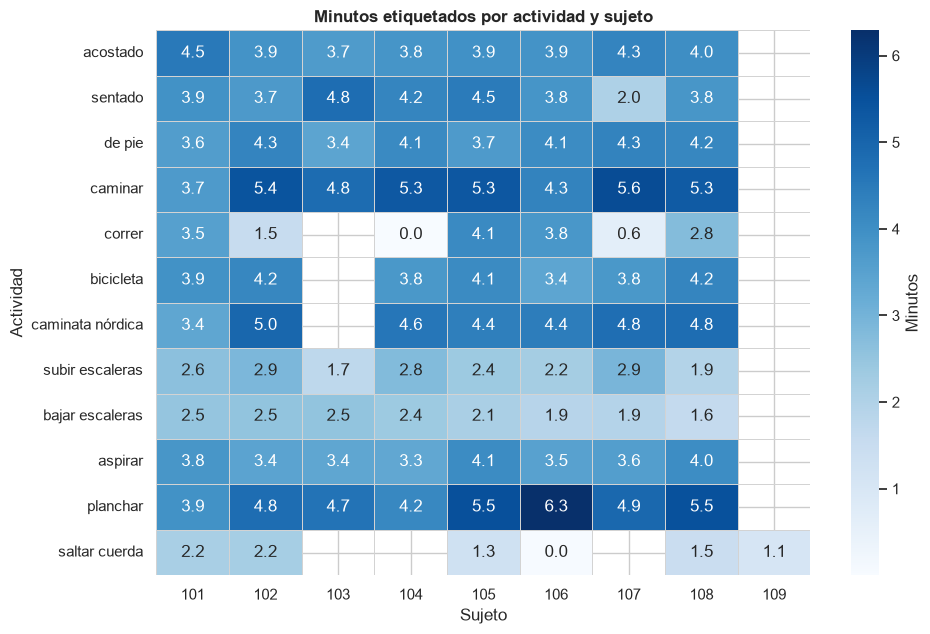

Minutos totales por sujeto:
sujeto
101    41.7
102    43.9
103    29.1
104    38.6
105    45.4
106    41.7
107    38.8
108    43.7
109     1.1


In [5]:
# Minutos etiquetados por actividad (filas) y sujeto (columnas)
minutos = datos.minutos_por_actividad_sujeto(df)

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.heatmap(
    minutos, annot=True, fmt=".1f", cmap="Blues",
    mask=minutos == 0,  # las celdas vacías quedan en blanco: actividad ausente
    cbar_kws={"label": "Minutos"}, linewidths=0.5, linecolor="lightgray", ax=ax,
)
ax.set_title("Minutos etiquetados por actividad y sujeto")
ax.set_xlabel("Sujeto")
ax.set_ylabel("Actividad")
plt.tight_layout()
guardar_figura(fig, "eda_01_minutos_actividad_sujeto", FIGURAS)
plt.show()

print("Minutos totales por sujeto:")
print(minutos.sum(axis=0).round(1).to_string())

Los sujetos 101 a 108 aportan entre 29 y 45 minutos cada uno, repartidos de forma bastante pareja: la mayoría de las celdas está entre 2 y 6 minutos. La excepción es correr, que varía mucho entre personas (0.6 min en el 107, 1.5 en el 102 y 4.1 en el 105). El **sujeto 109 es la excepción: solo 1.1 minutos, todos de saltar cuerda**. Las celdas en blanco son actividades que el sujeto no realizó: el 103 no hizo bicicleta, caminata nórdica, correr ni saltar cuerda, y saltar cuerda es la actividad con menos participantes.

Algunas celdas aparecen con 0.0 minutos pero no están en blanco. Son residuos de etiquetado muy cortos; los listamos:

In [6]:
# Celdas con datos, pero menos de una ventana (5.12 s): no van a generar ventanas
segundos = minutos * 60
residuos = segundos[(segundos > 0) & (segundos < 5.12)].stack().dropna()
print("Actividad y sujeto con datos de menos de 5.12 s:")
print(residuos.rename("segundos").round(2).to_string())

Actividad y sujeto con datos de menos de 5.12 s:
actividad      sujeto
correr         104       0.01
saltar cuerda  106       2.56


El sujeto 106 tiene 2.56 s etiquetados como saltar cuerda y el 104 tiene una sola muestra (0.01 s) etiquetada como correr. Ninguno alcanza para formar una ventana de 5.12 s, así que en la práctica **saltar cuerda tiene 5 sujetos (101, 102, 105, 108 y 109) y correr tiene 6** (falta en 103 y 104).

> **Decisión.** Se conservan los 9 sujetos, incluido el 109. Su fold en LOSO solo contiene saltar cuerda, así que su F1 macro será el de una sola clase: por eso el resumen de LOSO se reportará con y sin ese fold. El 109 no se pondrá en la prueba fija del esquema C, porque una sola actividad no permite evaluar al modelo completo. Al elegir los 3 sujetos de C hay que incluir al menos uno con saltar cuerda y uno con correr.

### 2.2 Distribución de clases en ventanas

El modelo clasifica ventanas, no muestras, así que medimos el desbalance en ventanas. Usamos la segmentación de `src/ventanas.py`: ventanas de 512 muestras (5.12 s) con paso de 256 (50 % de traslape), generadas solo dentro de tramos contiguos de la misma actividad y el mismo sujeto. El detalle de esta decisión está en el preprocesamiento; aquí solo contamos.

Además de cuántas ventanas tiene cada clase, contamos **cuántos sujetos** la aportan, porque para generalizar a personas nuevas importa más el número de personas que el número de ventanas.

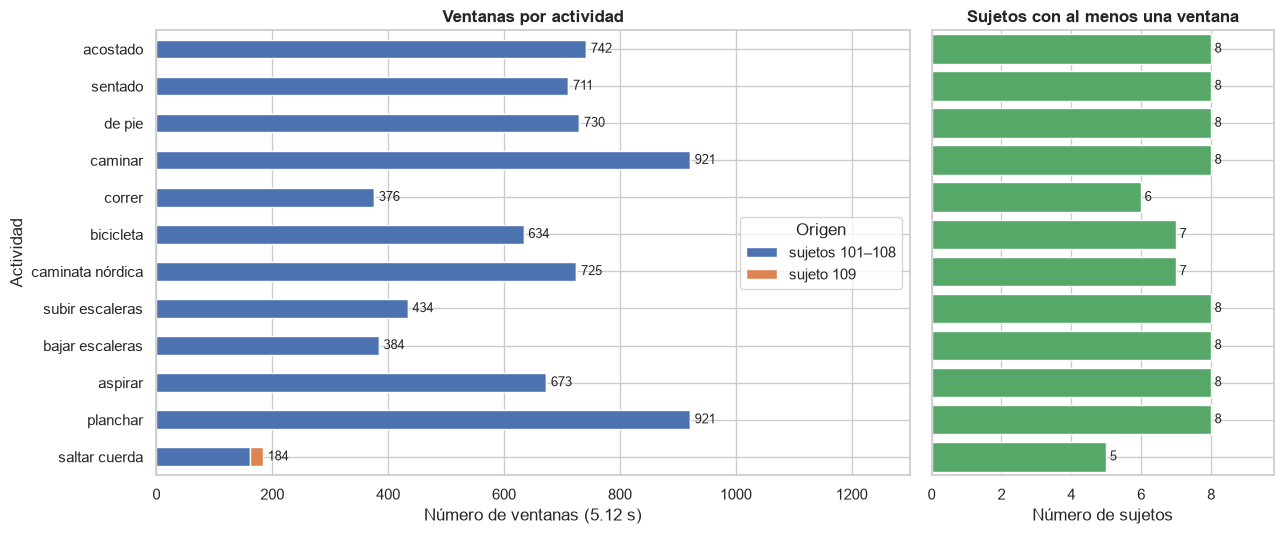

In [7]:
# Índices de las ventanas (sin calcular características todavía)
meta = ventanas.indices_ventanas(df)
orden = [a for a in datos.ACTIVIDADES.values()]

# Ventanas por actividad, separando la aportación del sujeto 109
por_actividad = (
    meta.assign(origen=np.where(meta["sujeto"] == 109, "sujeto 109", "sujetos 101–108"))
    .groupby(["actividad", "origen"]).size().unstack(fill_value=0)
    .reindex(orden)
)
sujetos_por_clase = meta.groupby("actividad")["sujeto"].nunique().reindex(orden)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True,
                               gridspec_kw={"width_ratios": [2.2, 1]})
por_actividad[["sujetos 101–108", "sujeto 109"]].plot(
    kind="barh", stacked=True, ax=ax1, color=["#4C72B0", "#DD8452"])
for i, total in enumerate(por_actividad.sum(axis=1)):
    ax1.text(total + 8, i, f"{total}", va="center", fontsize=9)
ax1.set_title("Ventanas por actividad")
ax1.set_xlabel("Número de ventanas (5.12 s)")
ax1.set_ylabel("Actividad")
ax1.invert_yaxis()
ax1.set_xlim(0, 1300)  # espacio a la derecha para la leyenda
ax1.legend(title="Origen", loc="center right")

ax2.barh(sujetos_por_clase.index, sujetos_por_clase.values, color="#55A868")
for i, n in enumerate(sujetos_por_clase.values):
    ax2.text(n + 0.1, i, str(n), va="center", fontsize=9)
ax2.set_title("Sujetos con al menos una ventana")
ax2.set_xlabel("Número de sujetos")
ax2.set_xlim(0, 9.8)
plt.tight_layout()
guardar_figura(fig, "eda_02_ventanas_y_sujetos_por_clase", FIGURAS)
plt.show()

Planchar y caminar son las clases más grandes (921 ventanas cada una) y saltar cuerda la más pequeña (184). La gráfica de la derecha muestra un segundo desbalance, menos visible: saltar cuerda viene de **5 personas** y correr de 6, mientras que la mayoría de las clases viene de 8. Toda la aportación del sujeto 109 (en naranja) es a saltar cuerda.

Comparamos las cifras con y sin el sujeto 109 para ver qué cambia al conservarlo:

In [8]:
def resumen_desbalance(m):
    """Total de ventanas, ventanas de saltar cuerda y razón mayor/menor clase."""
    conteo = m["actividad"].value_counts()
    return {
        "ventanas": len(m),
        "saltar cuerda": conteo["saltar cuerda"],
        "saltar cuerda (%)": round(conteo["saltar cuerda"] / len(m) * 100, 1),
        "clase mayor / menor": round(conteo.max() / conteo.min(), 1),
    }


tabla_109 = pd.DataFrame({
    "Con el 109 (se usa)": resumen_desbalance(meta),
    "Sin el 109 (propuesta original)": resumen_desbalance(meta[meta["sujeto"] != 109]),
}).T.astype({"ventanas": int, "saltar cuerda": int})
tabla_109.to_csv(RESULTADOS / "eda_desbalance_con_sin_109.csv")
tabla_109

,ventanas,saltar cuerda,saltar cuerda (%),clase mayor / menor
Con el 109 (se usa),7435,184,2.5,5.0
Sin el 109 (propuesta original),7412,161,2.2,5.7


Hay **7 435 ventanas** con los 9 sujetos. Incluir al 109 agrega 23 ventanas, todas de saltar cuerda: la clase minoritaria pasa de 161 a 184 ventanas (de 2.2 % a 2.5 %) y el desbalance baja de 5.7 : 1 a **5.0 : 1**. Aporta poco en volumen, pero suma una quinta persona a la clase con menos personas, que es justo lo que importa al evaluar con sujetos nuevos.

> **Decisión.** Con un desbalance de 5 : 1 la exactitud premiaría acertar las clases grandes, así que la **métrica principal es el F1 macro**, que pesa igual a todas las actividades. En la partición aleatoria A se estratifica por clase. Se probarán pesos por clase (`class_weight="balanced"`) contra no balancear. Como saltar cuerda tiene pocas personas y no solo pocas ventanas, esperamos que sea la clase más difícil en LOSO; ningún remuestreo crea personas nuevas, y ese es uno de los motivos para no usar SMOTE.

### 2.3 Valores faltantes por grupo de sensores

Medimos qué porcentaje de las muestras etiquetadas tiene algún NaN en cada grupo de sensores, y de qué tamaño son los huecos. Si los huecos son cortos, interpolar es razonable; si fueran largos, habría que descartar tramos.

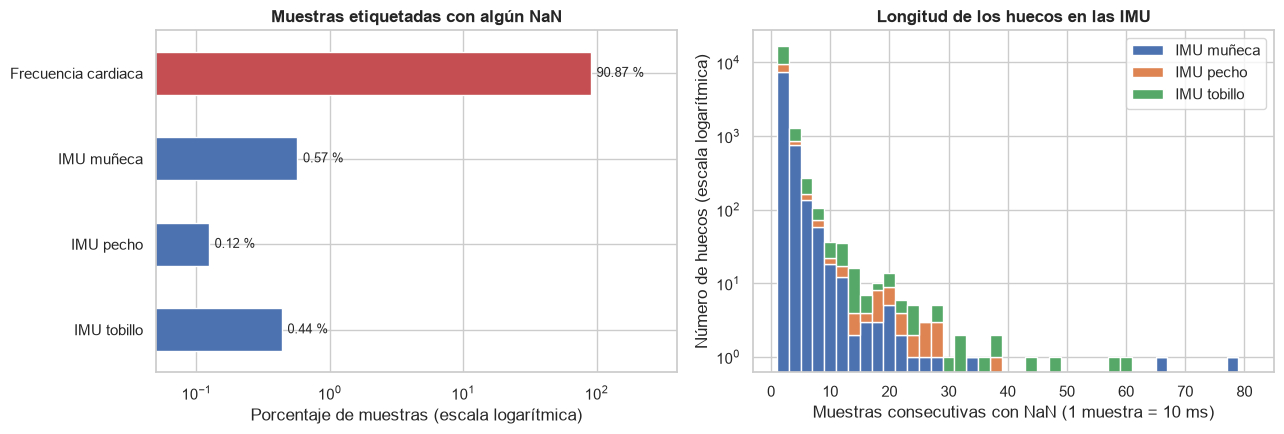

Huecos en IMU: 18,557; mediana 1 muestras; 99.4 % duran ≤ 10 muestras (0.1 s); el más largo dura 77 muestras (0.77 s)
Frecuencia cardiaca: mediana entre lecturas 0.11 s (≈ 9.1 Hz)


In [9]:
etiquetadas = df[df["actividad_id"] != 0]

# Porcentaje de muestras etiquetadas con al menos un NaN, por grupo de sensores
grupos = {"Frecuencia cardiaca": ["fc"]}
for ubicacion in datos.UBICACIONES:
    cols = [c for c in df.columns if c.startswith(f"{ubicacion}_") and "orient" not in c]
    grupos[f"IMU {datos.NOMBRE_UBICACION[ubicacion]}"] = cols
pct_nan = pd.Series({g: etiquetadas[c].isna().any(axis=1).mean() * 100 for g, c in grupos.items()})

# Longitud de cada hueco en las IMU (todas sus columnas se pierden juntas)
huecos = {u: datos.huecos_nan(df, f"{u}_acc16_x") for u in datos.UBICACIONES}

# Separación entre lecturas válidas consecutivas de la frecuencia cardiaca
dt_fc = df.loc[df["fc"].notna()].groupby("sujeto")["tiempo"].diff().dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
pct_nan.plot(kind="barh", ax=ax1, color=["#C44E52"] + ["#4C72B0"] * 3, logx=True)
for i, v in enumerate(pct_nan.values):
    ax1.text(v * 1.1, i, f"{v:.2f} %", va="center", fontsize=9)
ax1.set_title("Muestras etiquetadas con algún NaN")
ax1.set_xlabel("Porcentaje de muestras (escala logarítmica)")
ax1.set_xlim(0.05, 400)
ax1.invert_yaxis()

todos = np.concatenate(list(huecos.values()))
ax2.hist([huecos[u] for u in datos.UBICACIONES], bins=np.arange(1, 82, 2),
         label=[f"IMU {datos.NOMBRE_UBICACION[u]}" for u in datos.UBICACIONES], stacked=True)
ax2.set_yscale("log")
ax2.set_title("Longitud de los huecos en las IMU")
ax2.set_xlabel("Muestras consecutivas con NaN (1 muestra = 10 ms)")
ax2.set_ylabel("Número de huecos (escala logarítmica)")
ax2.legend()
plt.tight_layout()
guardar_figura(fig, "eda_03_faltantes", FIGURAS)
plt.show()

print(f"Huecos en IMU: {len(todos):,}; mediana {np.median(todos):.0f} muestras; "
      f"{(todos <= 10).mean() * 100:.1f} % duran ≤ 10 muestras (0.1 s); "
      f"el más largo dura {todos.max()} muestras ({todos.max() / datos.FS:.2f} s)")
print(f"Frecuencia cardiaca: mediana entre lecturas {dt_fc.median():.2f} s "
      f"(≈ {1 / dt_fc.median():.1f} Hz)")

Hay dos tipos de faltantes muy distintos:

- **Frecuencia cardiaca (90.9 % de NaN):** no es pérdida de datos. El monitor mide cada 0.11 s (≈ 9 Hz) y el archivo tiene una fila cada 0.01 s, así que 10 de cada 11 filas quedan vacías por construcción.
- **IMU (entre 0.12 % y 0.57 % de las muestras):** son pérdidas reales de la conexión inalámbrica. Cuando falla un paquete se pierden todas las columnas de esa IMU a la vez (el porcentaje es igual para sus 15 columnas). Los huecos son muy cortos: la mitad es de una sola muestra, más del 99 % dura 0.1 s o menos, y el más largo dura 0.77 s.

> **Decisión.** La frecuencia cardiaca se interpola linealmente y después se rellenan los extremos con `ffill`/`bfill`. Las IMU se interpolan linealmente con un límite de **100 muestras (1 s)**, que cubre todos los huecos observados (el máximo es de 77). La interpolación se hace por sujeto y en orden temporal, usando solo la propia señal de ese sujeto, sin etiquetas ni datos de otros sujetos, así que no filtra información entre entrenamiento y prueba.

### 2.4 Señal de ejemplo por actividad

Graficamos 10 s de la magnitud de la aceleración del tobillo para cuatro actividades del sujeto 101. Usamos la magnitud porque no depende de cómo quedó orientado el sensor. La franja sombreada marca la duración de una ventana (5.12 s).

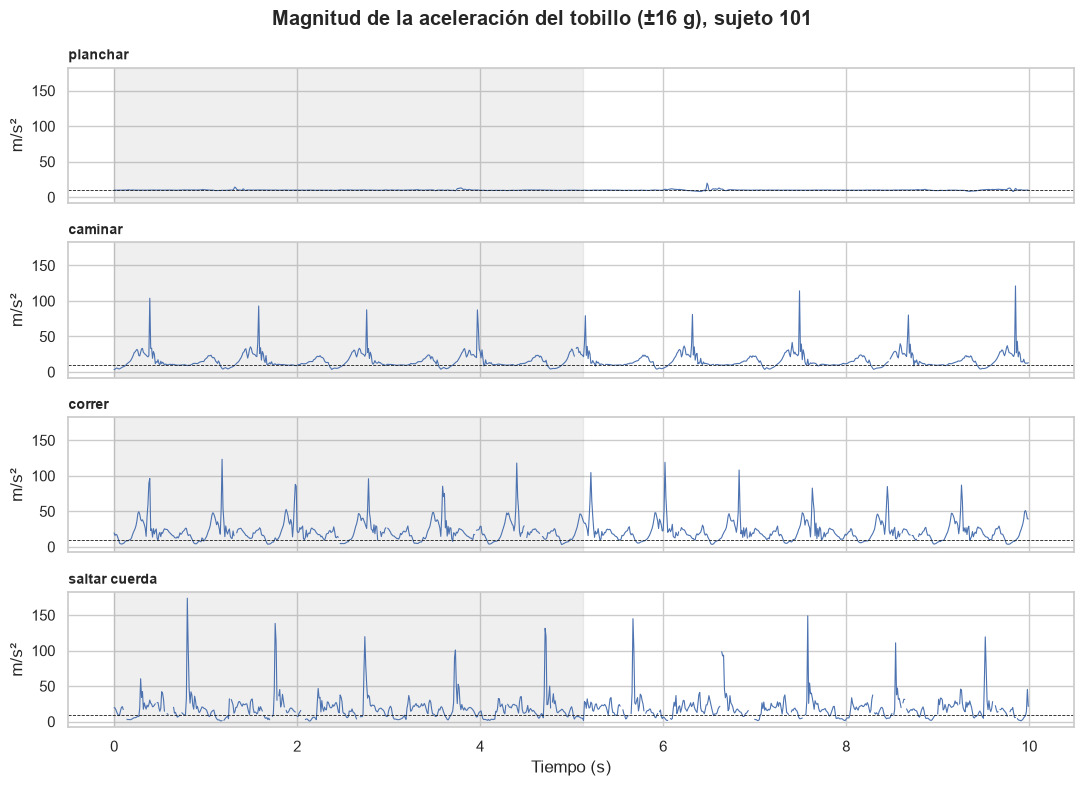

In [10]:
def tramo_central(d_sujeto, actividad, segundos=10):
    """Toma `segundos` del centro del tramo más largo de una actividad."""
    d = d_sujeto[d_sujeto["actividad"] == actividad]
    seg = ventanas.segmentos_contiguos(d)
    mayor = pd.Series(seg).value_counts().idxmax()
    d = d[seg == mayor]
    centro, n = len(d) // 2, segundos * datos.FS
    return d.iloc[centro - n // 2: centro + n // 2]


actividades_ejemplo = ["planchar", "caminar", "correr", "saltar cuerda"]
d101 = df[df["sujeto"] == 101]

fig, ejes = plt.subplots(len(actividades_ejemplo), 1, figsize=(11, 8), sharex=True, sharey=True)
for ax, actividad in zip(ejes, actividades_ejemplo):
    tramo = tramo_central(d101, actividad)
    t = tramo["tiempo"] - tramo["tiempo"].iloc[0]
    ax.plot(t, datos.magnitud(tramo, "tobillo"), lw=0.8)
    ax.axvspan(0, 5.12, color="gray", alpha=0.12)
    ax.axhline(9.81, color="k", lw=0.6, ls="--")
    ax.set_title(actividad, loc="left", fontsize=10)
    ax.set_ylabel("m/s²")
ejes[-1].set_xlabel("Tiempo (s)")
fig.suptitle("Magnitud de la aceleración del tobillo (±16 g), sujeto 101", fontweight="bold")
plt.tight_layout()
guardar_figura(fig, "eda_04_senal_ejemplo", FIGURAS)
plt.show()

La línea punteada es la gravedad (9.81 m/s²), que es lo que mide el acelerómetro en reposo. Al planchar, el tobillo casi no se mueve y la señal se queda pegada a la gravedad. Caminar, correr y saltar cuerda son **periódicas**: cada pico es un impacto del pie. Lo interesante es que la altura de los picos no basta para separarlas, porque al caminar y al correr llegan a valores parecidos (≈ 100 m/s²). Lo que sí cambia es el **ritmo**: al caminar hay un impacto cada ~1.2 s y al correr cada ~0.8 s. Saltar cuerda tiene los picos más altos (hasta ≈ 170 m/s²) y, entre ellos, rebotes pequeños que no aparecen en las otras. En la franja de 5.12 s caben entre 4 y 6 ciclos de cada actividad periódica. Los pequeños cortes en la línea son muestras faltantes por la conexión inalámbrica (§2.3).

> **Decisión.** Las ventanas de 5.12 s (las que usan Reiss y Stricker, 2012) contienen varios ciclos de cada actividad periódica, así que bastan para describirlas. Como las actividades se distinguen por su ritmo y no solo por su intensidad, además de estadísticas en el tiempo (media, desviación, mínimo, máximo, RMS) se extraerán **características espectrales** (energía, frecuencia dominante y entropía espectral). Se usará la magnitud, además de los tres ejes, por ser robusta a la orientación del sensor.

### 2.5 Acelerómetro de ±6 g contra ±16 g

Cada IMU tiene dos acelerómetros. La documentación advierte que el de ±6 g se satura con impactos fuertes y recomienda el de ±16 g. Lo comprobamos en las dos actividades de mayor impacto, correr y saltar cuerda: buscamos qué tan seguido el de ±6 g llega a su valor máximo y si el de ±16 g pasa de 6 g en esos mismos instantes.

In [11]:
G = 9.81  # aceleración de la gravedad (m/s²)
filas = []
for actividad in ["correr", "saltar cuerda"]:
    d = etiquetadas[etiquetadas["actividad"] == actividad]
    for u in datos.UBICACIONES:
        a6 = d[[f"{u}_acc6_{e}" for e in "xyz"]].abs()
        a16 = d[[f"{u}_acc16_{e}" for e in "xyz"]].abs()
        # Tope empírico del ±6 g: el máximo absoluto observado en toda la sesión etiquetada
        tope = etiquetadas[[f"{u}_acc6_{e}" for e in "xyz"]].abs().max().max()
        filas.append({
            "actividad": actividad, "IMU": datos.NOMBRE_UBICACION[u],
            "tope ±6 g (m/s²)": round(float(tope), 1),
            "% muestras ±6 g en el tope": round((a6 >= 0.99 * tope).any(axis=1).mean() * 100, 2),
            "% muestras ±16 g > 6 g": round((a16 > 6 * G).any(axis=1).mean() * 100, 2),
            "máximo ±16 g (m/s²)": round(float(a16.max().max()), 1),
        })
saturacion = pd.DataFrame(filas)
saturacion.to_csv(RESULTADOS / "eda_saturacion_acc6.csv", index=False)
saturacion

,actividad,IMU,tope ±6 g (m/s²),% muestras ±6 g en el tope,% muestras ±16 g > 6 g,máximo ±16 g (m/s²)
0,correr,muñeca,62.3,1.80,2.53,155.7
1,correr,pecho,61.9,0.00,0.00,58.3
2,correr,tobillo,62.3,0.44,2.00,158.9
3,saltar cuerda,muñeca,62.3,0.00,0.01,157.8
4,saltar cuerda,pecho,61.9,0.54,0.89,153.6
5,saltar cuerda,tobillo,62.3,0.35,1.66,157.4


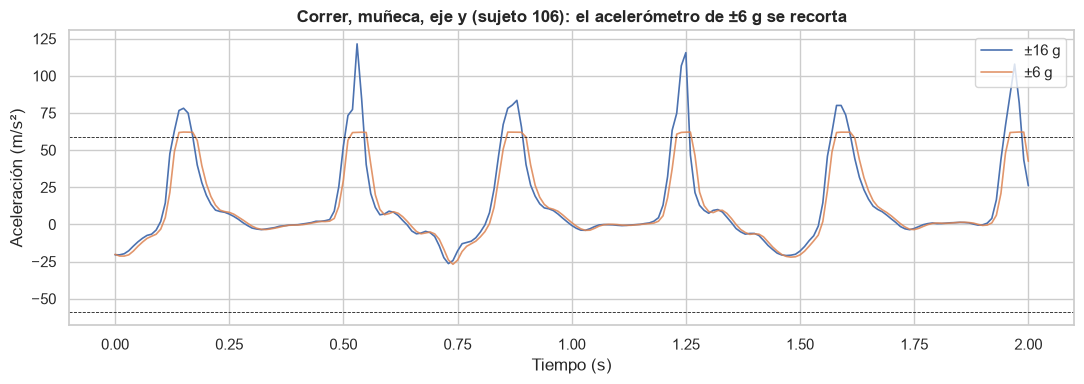

In [12]:
# Tramo de 2 s de correr (muñeca) sin faltantes y con más muestras saturadas en el ±6 g
corr = etiquetadas[etiquetadas["actividad"] == "correr"]
tope_muneca = etiquetadas[[f"muneca_acc6_{e}" for e in "xyz"]].abs().max().max()
eje = corr[[f"muneca_acc6_{e}" for e in "xyz"]].abs().ge(0.99 * tope_muneca).sum().idxmax()[-1]
saturada = corr[f"muneca_acc6_{eje}"].abs().ge(0.99 * tope_muneca)
con_nan = corr[[f"muneca_acc16_{eje}", f"muneca_acc6_{eje}"]].isna().any(axis=1)
puntaje = saturada.rolling(200, center=True).sum()
puntaje[con_nan.rolling(200, center=True).sum() > 0] = -1  # descarta tramos con huecos
centro = puntaje.idxmax()
tramo = df.loc[centro - 100: centro + 100]
t = tramo["tiempo"] - tramo["tiempo"].iloc[0]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, tramo[f"muneca_acc16_{eje}"], label="±16 g", lw=1.2)
ax.plot(t, tramo[f"muneca_acc6_{eje}"], label="±6 g", lw=1.2, alpha=0.85)
for signo in (1, -1):
    ax.axhline(signo * 6 * G, color="k", ls="--", lw=0.6)
ax.set_title(f"Correr, muñeca, eje {eje} (sujeto {int(tramo['sujeto'].iloc[0])}): el acelerómetro de ±6 g se recorta")
ax.set_xlabel("Tiempo (s)")
ax.set_ylabel("Aceleración (m/s²)")
ax.legend(loc="upper right")
plt.tight_layout()
guardar_figura(fig, "eda_05_saturacion_acc6", FIGURAS)
plt.show()

El acelerómetro de ±6 g nunca pasa de unos 62 m/s² (≈ 6.3 g), mientras que el de ±16 g llega hasta unos 159 m/s² (≈ 16 g) en la misma IMU. En la gráfica se ve el efecto: en los impactos de la carrera la señal de ±6 g se queda plana en el tope mientras la de ±16 g sigue subiendo. Las muestras recortadas son pocas en porcentaje (1.8 % al correr, en la muñeca), pero están justo en los picos, que son lo que distingue a las actividades de alto impacto.

> **Decisión.** Se usa solo el acelerómetro de **±16 g** y se descarta el de ±6 g, como recomienda la documentación. Ambos miden lo mismo, así que conservar los dos solo duplicaría información, y en las actividades intensas el de ±6 g la deforma.

### 2.6 Similitud entre ventanas

Esta subsección compara la distancia entre ventanas consecutivas del mismo sujeto, entre ventanas no vecinas del mismo sujeto y entre ventanas de sujetos distintos en la misma actividad. Es la evidencia directa del mecanismo de fuga de P1. Necesita las características por ventana, así que se presenta en el **§3.4**, después de calcularlas.

### Resumen de decisiones del análisis exploratorio

| Hallazgo | Decisión |
|---|---|
| El sujeto 109 solo tiene 1.1 min de saltar cuerda | Se conserva; LOSO se reporta con y sin su fold; no entra en la prueba de C |
| Saltar cuerda: 5 sujetos; correr: 6 (106 y 104 solo tienen residuos < 5.12 s) | Los 3 sujetos de prueba de C deben incluir saltar cuerda y correr |
| Desbalance de 5.0 : 1 en ventanas, y también de personas | F1 macro como métrica principal; estratificación en A; experimento de pesos por clase; sin SMOTE |
| La FC tiene 90.9 % de NaN por su frecuencia de muestreo | Interpolación lineal y `ffill`/`bfill` por sujeto |
| Huecos en las IMU cortos (máx. 0.77 s) | Interpolación lineal por sujeto con límite de 1 s |
| Actividades periódicas que se distinguen por ritmo | Ventanas de 5.12 s y características espectrales |
| El acelerómetro de ±6 g se satura | Usar solo el de ±16 g |
| La orientación es inválida (documentación) | Descartar esas 12 columnas |
| Ventanas vecinas se parecen más que las de otra persona (§3.4) | Esquema A′ para separar la fuga por vecindad de la variabilidad entre personas |

## 3. Preprocesamiento

En esta sección pasamos de muestras crudas a una tabla con **una fila por ventana y una columna por característica**, que es lo que reciben los modelos. Aplicamos las decisiones del análisis exploratorio en este orden: limpieza e interpolación, ventanas y características.

Una regla atraviesa toda la sección: **aquí no se ajusta nada que aprenda de varios datos a la vez**. Cada paso usa solo la señal de un sujeto (interpolación) o solo las muestras de una ventana (características). El escalado, la selección de atributos y el PCA sí aprenden de los datos, así que van dentro del `Pipeline` del modelado y se ajustan solo con el entrenamiento de cada fold.

### 3.1 Limpieza e interpolación

Descartamos las 12 columnas de orientación (inválidas según la documentación) y las 9 del acelerómetro de ±6 g (se satura, §2.5). **No descartamos al sujeto 109.** Luego interpolamos con `interpolar_por_sujeto` de `src/datos.py`:

- **Frecuencia cardiaca:** interpolación lineal y después `ffill`/`bfill` para los extremos.
- **IMU:** interpolación lineal solo dentro de huecos de hasta 100 muestras (1 s).

Interpolamos **por sujeto, en orden temporal y sobre la secuencia completa**, incluidas las muestras transitorias. Si primero quitáramos las transiciones, la interpolación uniría dos tramos que en realidad estaban separados. Las muestras transitorias no se usan después, porque ninguna ventana las incluye.

¿Por qué esto no filtra información de prueba? Cada valor se rellena con las muestras vecinas en el tiempo **del mismo sujeto**, sin mirar etiquetas ni a otros sujetos. Es lo mismo que podría hacer un dispositivo en tiempo real con la señal de su propio usuario.

In [13]:
# Limpieza (quita orientación y ±6 g) e interpolación por sujeto
señales_modelo = datos.columnas_modelo(df)
datos_limpios = datos.interpolar_por_sujeto(df)

etiq_antes = df.loc[df["actividad_id"] != 0, señales_modelo]
etiq_despues = datos_limpios.loc[datos_limpios["actividad_id"] != 0, señales_modelo]

print(f"Columnas de señal: {df.shape[1] - 4} originales → {len(señales_modelo)} conservadas")
print(f"Muestras etiquetadas con algún NaN: {etiq_antes.isna().any(axis=1).mean() * 100:.2f} % antes "
      f"→ {etiq_despues.isna().any(axis=1).mean() * 100:.2f} % después")
print(f"Sujetos presentes: {sorted(int(s) for s in datos_limpios['sujeto'].unique())}")

Columnas de señal: 52 originales → 31 conservadas
Muestras etiquetadas con algún NaN: 90.97 % antes → 0.00 % después
Sujetos presentes: [101, 102, 103, 104, 105, 106, 107, 108, 109]


Pasamos de 52 a 31 columnas de señal: la frecuencia cardiaca y, por cada IMU, temperatura, acelerómetro de ±16 g, giroscopio y magnetómetro. Después de interpolar ya no queda ningún NaN en las muestras etiquetadas, lo que confirma que el límite de 1 s cubre todos los huecos reales de las IMU.

### 3.2 Ventanas

Cortamos ventanas de **512 muestras (5.12 s) con paso de 256 (50 % de traslape)**, las mismas de Reiss y Stricker (2012). Una ventana solo se forma dentro de un **segmento contiguo**: un tramo sin interrupciones del mismo sujeto haciendo la misma actividad. Así ninguna ventana mezcla dos actividades ni cruza una transición.

Para cada ventana guardamos `sujeto`, `actividad`, `segmento` (identificador del tramo contiguo) y `posicion` (su orden dentro del tramo). El esquema A′ de la Fase 3 los necesita para formar bloques temporales y quitar las ventanas vecinas.

In [14]:
# Índices de las ventanas sobre los datos ya interpolados
meta = ventanas.indices_ventanas(datos_limpios)

# Verificación: ninguna ventana mezcla actividades ni sujetos
actividad_arr = datos_limpios["actividad_id"].to_numpy()
sujeto_arr = datos_limpios["sujeto"].to_numpy()
idx = meta["inicio"].to_numpy()[:, None] + np.arange(ventanas.LARGO_VENTANA)
assert (actividad_arr[idx] == meta["actividad_id"].to_numpy()[:, None]).all()
assert (sujeto_arr[idx] == meta["sujeto"].to_numpy()[:, None]).all()

# Verificación: dentro de un segmento, ventanas consecutivas comparten la mitad de sus muestras
mismo_seg = meta["segmento"].eq(meta["segmento"].shift(-1))
assert (meta["inicio"].shift(-1)[mismo_seg] - meta["inicio"][mismo_seg]).eq(ventanas.PASO_VENTANA).all()

assert len(meta) == 7435, "El número de ventanas no coincide con el esperado"
print(f"Ventanas: {len(meta):,} · segmentos contiguos: {meta['segmento'].nunique()} · "
      f"ventanas por segmento: mediana {meta.groupby('segmento').size().median():.0f}")
meta.head()

Ventanas: 7,435 · segmentos contiguos: 106 · ventanas por segmento: mediana 85


,sujeto,actividad_id,actividad,segmento,posicion,inicio,fin
0,101,1,acostado,2,0,2928,3440
1,101,1,acostado,2,1,3184,3696
2,101,1,acostado,2,2,3440,3952
3,101,1,acostado,2,3,3696,4208
4,101,1,acostado,2,4,3952,4464


Obtenemos las **7 435 ventanas** esperadas, repartidas en 106 segmentos, y las verificaciones confirman que ninguna ventana cruza un cambio de actividad o de sujeto. Cada segmento aporta una mediana de 85 ventanas, cada una casi idéntica a sus vecinas. Ese es el material del que se alimenta la fuga en la partición aleatoria.

### 3.3 Características por ventana

Resumimos cada ventana en un vector de números con `extraer_caracteristicas` de `src/caracteristicas.py`. Cada característica se calcula **solo con las 512 muestras de su ventana**.

**Señales (24):** para cada IMU (muñeca, pecho y tobillo), el acelerómetro de ±16 g y el giroscopio, en sus ejes x, y, z y su magnitud. La magnitud no depende de cómo quedó orientado el sensor (§2.4).

**Estadísticas por señal (8):**

| Tipo | Característica | Qué captura |
|---|---|---|
| Tiempo | media, desviación estándar, mínimo, máximo, RMS | Postura (la media capta la dirección de la gravedad) e intensidad del movimiento |
| Frecuencia | energía | Cuánto movimiento hay, sin contar el nivel medio |
| Frecuencia | frecuencia dominante (Hz) | El ritmo: pasos, pedaleo o saltos por segundo (§2.4) |
| Frecuencia | entropía espectral (0 a 1) | Si el movimiento es rítmico (baja) o irregular (alta) |

Para las espectrales usamos la FFT con `fs = 100` Hz, restando la media de la ventana e ignorando la componente de 0 Hz, para que describan el movimiento y no la gravedad.

**Otras (4):** frecuencia cardiaca media y temperatura media de cada IMU.

En total son 24 × 8 + 4 = **196 características**.

In [15]:
# Matriz de características, etiquetas y grupos (sujeto) para el modelado
X = caracteristicas.extraer_caracteristicas(datos_limpios, meta)
y = meta["actividad"].to_numpy()
grupos = meta["sujeto"].to_numpy()

assert X.shape[0] == len(meta) == 7435
assert not X.isna().any().any(), "Hay NaN en las características"

print(f"X: {X.shape[0]:,} ventanas × {X.shape[1]} características")
print(f"NaN en X: {int(X.isna().sum().sum())}")
print(f"Clases: {len(np.unique(y))} · sujetos: {len(np.unique(grupos))}")
print("\nEjemplos de nombres:", ", ".join(X.columns[[0, 7, 31, 100, -4, -1]]))
X.iloc[:5, :8]

X: 7,435 ventanas × 196 características
NaN en X: 0
Clases: 12 · sujetos: 9

Ejemplos de nombres: muneca_acc_x_media, muneca_acc_x_entropia, muneca_acc_mag_entropia, pecho_gyro_x_rms, fc_media, tobillo_temp_media


,muneca_acc_x_media,muneca_acc_x_std,muneca_acc_x_min,muneca_acc_x_max,muneca_acc_x_rms,muneca_acc_x_energia,muneca_acc_x_frec_dom,muneca_acc_x_entropia
0,-0.545526,1.672094,-3.36202,3.184930,1.758834,715.751979,0.195312,0.315021
1,-1.844572,1.131534,-4.66001,0.879367,2.163982,327.780168,0.195312,0.450808
2,-2.900060,3.945938,-12.91580,3.032050,4.897017,3986.049073,0.390625,0.289742
3,-3.382686,4.695902,-14.09040,3.032050,5.787405,5645.183712,0.195312,0.191863
4,-1.498833,3.305366,-14.09040,3.138840,3.629317,2796.939709,0.195312,0.347415


La matriz final tiene **7 435 ventanas × 196 características**, sin NaN, con 12 clases y 9 sujetos. Los nombres se leen de izquierda a derecha: ubicación, sensor, eje y estadística (por ejemplo, `tobillo_acc_mag_std` es la desviación estándar de la magnitud de la aceleración del tobillo).

Junto con `X` guardamos `y` (la actividad de cada ventana) y `grupos` (su sujeto). `grupos` es lo que usan LOSO y el esquema C para que ningún sujeto quede a la vez en entrenamiento y prueba.

Una advertencia que retomaremos en P3: la **temperatura** de cada IMU cambia lentamente durante la sesión y es distinta para cada persona. Puede funcionar como una «huella» del sujeto y del momento de la sesión más que de la actividad. En la partición aleatoria eso ayuda a reconocer a la ventana gemela; con personas nuevas, probablemente no.

### 3.4 Similitud entre ventanas: el mecanismo de la fuga

*(Es la subsección §2.6 del análisis exploratorio; está aquí porque necesita las características.)*

Antes de entrenar cualquier modelo, comprobamos directamente la idea que motiva P1. Medimos qué tan parecidas son dos ventanas con la distancia euclidiana entre sus vectores de características, en tres tipos de pares:

- **(a) consecutivas:** el mismo sujeto y segmento, una justo después de la otra (comparten 2.56 s de señal);
- **(b) no vecinas del mismo sujeto:** el mismo sujeto y actividad, sin compartir ninguna muestra;
- **(c) de otro sujeto:** la misma actividad, hecha por otra persona.

Si la fuga existe, (a) debe estar mucho más cerca que (c). En la partición aleatoria el modelo tiene pares tipo (a) a ambos lados; en LOSO solo tiene pares tipo (c). El grupo (b) es el punto intermedio que buscará aislar el esquema A′.

Para que todas las características pesen igual en la distancia, las estandarizamos (media 0, desviación 1) con todas las ventanas. **Esta estandarización es solo descriptiva y no se reutiliza para modelar**; en el modelado el escalado se ajusta dentro de cada fold.

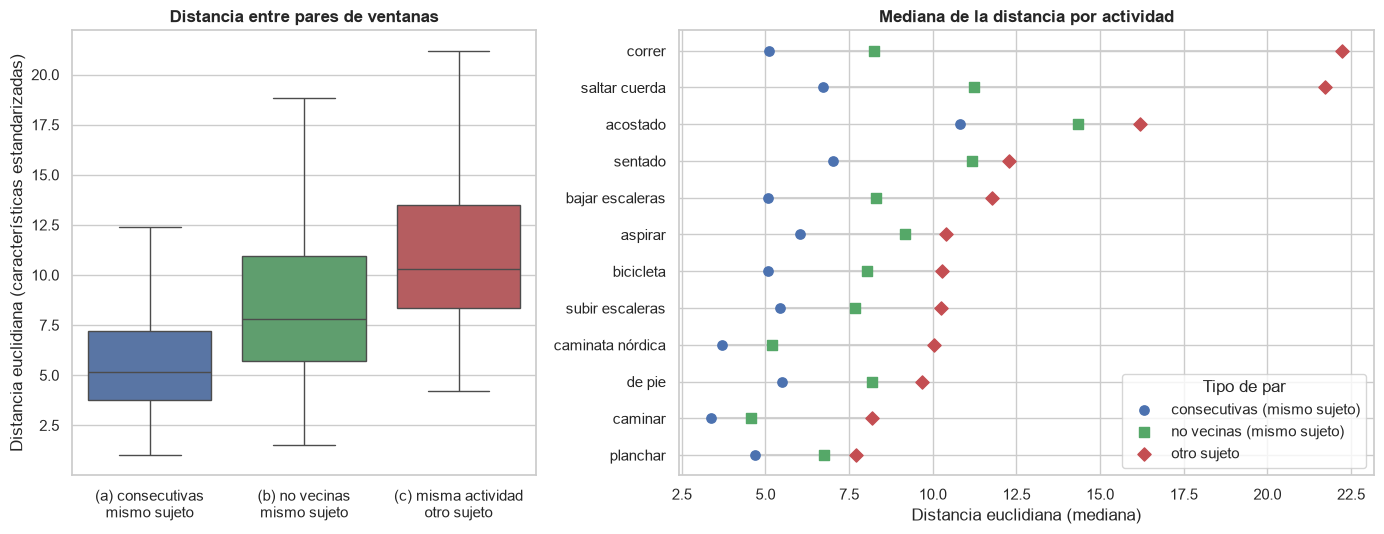

,count,25%,50%,75%
tipo de par,,,,
consecutivas (mismo sujeto),7329.0,3.77,5.13,7.22
no vecinas (mismo sujeto),7435.0,5.71,7.81,10.97
otro sujeto,7435.0,8.36,10.28,13.50


In [16]:
from sklearn.preprocessing import StandardScaler  # solo descriptivo, no se usa para modelar

# Distancia euclidiana entre ventanas en el espacio de características estandarizado
Z = StandardScaler().fit_transform(X)
pares = caracteristicas.pares_para_similitud(meta, seed=SEED)
actividad_meta = meta["actividad"].to_numpy()
distancias = pd.concat([
    pd.DataFrame({
        "tipo de par": tipo,
        "actividad": actividad_meta[p[:, 0]],
        "distancia": np.linalg.norm(Z[p[:, 0]] - Z[p[:, 1]], axis=1),
    })
    for tipo, p in pares.items()
], ignore_index=True)
tipos = list(pares.keys())
colores = dict(zip(tipos, ["#4C72B0", "#55A868", "#C44E52"]))

medianas = distancias.pivot_table(index="actividad", columns="tipo de par",
                                  values="distancia", aggfunc="median")[tipos]
medianas = medianas.sort_values("otro sujeto")
medianas.round(2).to_csv(RESULTADOS / "similitud_ventanas_por_actividad.csv")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})
sns.boxplot(data=distancias, x="tipo de par", y="distancia", order=tipos,
            hue="tipo de par", palette=colores, showfliers=False, ax=ax1)
ax1.set_title("Distancia entre pares de ventanas")
ax1.set_xlabel("")
ax1.set_ylabel("Distancia euclidiana (características estandarizadas)")
ax1.set_xticks(range(3), ["(a) consecutivas\nmismo sujeto", "(b) no vecinas\nmismo sujeto",
                          "(c) misma actividad\notro sujeto"])

for tipo, marcador in zip(tipos, ["o", "s", "D"]):
    ax2.scatter(medianas[tipo], medianas.index, label=tipo, color=colores[tipo], marker=marcador, s=45)
ax2.hlines(medianas.index, medianas.min(axis=1), medianas.max(axis=1), color="lightgray", zorder=0)
ax2.set_title("Mediana de la distancia por actividad")
ax2.set_xlabel("Distancia euclidiana (mediana)")
ax2.legend(title="Tipo de par", loc="lower right")
plt.tight_layout()
guardar_figura(fig, "eda_06_similitud_ventanas", FIGURAS)
plt.show()

resumen = distancias.groupby("tipo de par")["distancia"].describe()[["count", "25%", "50%", "75%"]].loc[tipos]
resumen.round(2)

Las tres distribuciones están ordenadas como predice el mecanismo de fuga. La mediana de la distancia es **5.1 entre ventanas consecutivas, 7.8 entre ventanas no vecinas del mismo sujeto y 10.3 entre la misma actividad de otro sujeto**. Una ventana se parece más a su vecina traslapada que a cualquier otra ventana de la misma persona, y se parece más a cualquier ventana de la misma persona que a la misma actividad hecha por otra.

Por actividad (derecha) aparecen dos patrones que anticipan P2:

- En **correr** y **saltar cuerda**, la distancia a otro sujeto (≈ 22) es más del doble que dentro del mismo sujeto. Cada persona corre y salta de forma muy propia, y además son las clases con menos personas (6 y 5). Son las candidatas a caer más en LOSO.
- En **planchar** y **caminar**, los tres tipos de pares están más juntos. Lo que distingue a estas actividades se parece más entre personas, así que deberían sufrir menos.

Las actividades estáticas (acostado, sentado) muestran distancias altas incluso entre ventanas consecutivas. Sin movimiento, las características espectrales describen sobre todo ruido del sensor, que cambia de una ventana a otra.

> **Decisión.** La evidencia respalda medir la brecha en dos pasos. La diferencia entre (a) y (b) es lo que el esquema **A′** debe quitar de la partición aleatoria (fuga por ventanas vecinas). La diferencia entre (b) y (c) es la **variabilidad entre personas**, que separa A′ de LOSO. En P2 contrastaremos la caída de F1 por clase con estas distancias, empezando por correr y saltar cuerda.

### Resumen del preprocesamiento

| Paso | Resultado |
|---|---|
| Limpieza | 52 → 31 columnas de señal (sin orientación ni ±6 g); los 9 sujetos se conservan |
| Interpolación por sujeto | 0 NaN en las muestras etiquetadas |
| Ventanas | 7 435 ventanas de 5.12 s en 106 segmentos contiguos; ninguna cruza un cambio de actividad |
| Características | `X` de 7 435 × 196, sin NaN; `y` con 12 clases; `grupos` con 9 sujetos |
| Ajustes aprendidos de los datos | Ninguno: escalado, selección y PCA van dentro del `Pipeline` de cada fold |

## 4. Modelado

### 4.1 Esquemas de partición

Definimos los cuatro esquemas una sola vez, en `src/particiones.py`, y **todos los modelos usan exactamente los mismos folds**.

| Esquema | Qué hace | Para qué sirve |
|---|---|---|
| **A** aleatoria | `StratifiedKFold(5, shuffle=True)`: mezcla las ventanas al azar | Evaluación «optimista», la más común en la literatura |
| **A′** bloques temporales | Cada segmento se divide en 5 bloques contiguos; el fold *k* prueba el bloque *k* de todos los segmentos. Del entrenamiento se quita la ventana vecina a cada bloque de prueba, porque comparte la mitad de su señal | Mismos sujetos que A, pero sin ventanas gemelas: aísla la fuga por vecindad |
| **B** LOSO | `LeaveOneGroupOut` por sujeto: 9 folds, uno por persona | Generalización a personas nuevas: la respuesta principal de P1 |
| **C** hold-out de 3 sujetos | Se apartan 3 sujetos antes de modelar, se entrena con los otros 6 y se evalúa una sola vez | Simula el uso real: un modelo final probado con personas nunca vistas |

**Elección de los sujetos de C.** El sujeto 109 queda fuera de la prueba porque solo tiene una actividad. Entre todas las combinaciones de 3 sujetos del 101 al 108 que incluyen al menos a uno con saltar cuerda y a uno con correr (§2.1), sorteamos una con `SEED = 42`. La elección quedó fija antes de entrenar cualquier modelo y no se cambia después de ver resultados.

La siguiente celda construye los esquemas y verifica con `assert` las reglas contra la fuga: en B y C ningún sujeto aparece a ambos lados de un fold, y en A′ ninguna ventana de prueba comparte muestras con una de entrenamiento.

In [17]:
from src import particiones, experimentos  # noqa: E402

# Folds externos de los 4 esquemas (las verificaciones contra la fuga van dentro)
esquemas = experimentos.preparar_esquemas(y, grupos, meta, seed=SEED)
SUJETOS_C = esquemas["C"]["sujetos_c"]

tamaños = pd.DataFrame([
    {"esquema": nombre, "folds": len(e["folds"]),
     "entrenamiento (media)": int(np.mean([len(tr) for tr, _ in e["folds"]])),
     "prueba (media)": int(np.mean([len(te) for _, te in e["folds"]]))}
    for nombre, e in esquemas.items()
]).set_index("esquema")

# Ventanas que A′ quita del entrenamiento por compartir muestras con la prueba
purgadas = [len(meta) - len(tr) - len(te) for tr, te in esquemas["A′"]["folds"]]
print(f"Sujetos de prueba en C: {SUJETOS_C}")
print(f"Actividades cubiertas por la prueba de C: "
      f"{meta.loc[meta['sujeto'].isin(SUJETOS_C), 'actividad'].nunique()} de 12")
print(f"Ventanas vecinas quitadas del entrenamiento en A′, por fold: {purgadas}")
print("Verificaciones contra la fuga: correctas\n")
tamaños

Sujetos de prueba en C: (101, 102, 107)
Actividades cubiertas por la prueba de C: 12 de 12
Ventanas vecinas quitadas del entrenamiento en A′, por fold: [106, 212, 212, 212, 106]
Verificaciones contra la fuga: correctas



,folds,entrenamiento (media),prueba (media)
esquema,,,
A,5,5948,1487
A′,5,5778,1487
B,9,6608,826
C,1,4581,2854


### 4.2 Modelos y búsqueda de hiperparámetros

Cada modelo es un `Pipeline`, de modo que el escalado se ajusta solo con el entrenamiento de cada fold:

| Modelo | Pipeline | Rejilla |
|---|---|---|
| Línea base «más frecuente» | `DummyClassifier("most_frequent")` | — |
| Línea base «estratificada» | `DummyClassifier("stratified")` | — |
| Random Forest | `RandomForestClassifier(n_estimators=200)` | `max_depth` ∈ {None, 20}, `min_samples_leaf` ∈ {1, 5} |
| SVM | `StandardScaler` → `SVC(kernel="rbf")` | `C` ∈ {1, 10, 100}, `gamma` ∈ {"scale", 0.01} |
| kNN (sonda de fuga) | `StandardScaler` → `KNeighborsClassifier` | `n_neighbors` ∈ {1, 5, 15}, `weights` ∈ {"uniform", "distance"} |

Las líneas base marcan el piso: un modelo que no supera a «más frecuente» o a «estratificada» no aprendió nada útil. Random Forest no necesita escalado y da importancias de atributos (P3). kNN es la **sonda de fuga**: clasifica copiando la etiqueta de las ventanas más parecidas, así que es el modelo que más debería beneficiarse de tener una ventana gemela en el entrenamiento (hipótesis previa).

**Búsqueda anidada.** Elegir hiperparámetros también es aprender de los datos. Si los eligiéramos mirando el fold de prueba, el resultado saldría optimista. Por eso, dentro de cada fold externo hacemos una búsqueda interna (`GridSearchCV` con `f1_macro`) que **solo ve el entrenamiento de ese fold**, y el ciclo interno **imita la separación del externo**:

| Esquema externo | Ciclo interno |
|---|---|
| A | `StratifiedKFold(4)` aleatorio |
| A′ | Un fold por cada uno de los 4 bloques restantes, también sin ventanas vecinas |
| B y C | `GroupKFold` por sujeto (4 folds en B, 3 en C, que solo tiene 6 sujetos para entrenar) |

Si en B el ciclo interno fuera aleatorio, elegiría los hiperparámetros que mejor aprovechan las ventanas gemelas, y volveríamos a meter fuga por la puerta de atrás.

**Comparación justa.** Todos los modelos usan las mismas 196 características, los mismos folds, la misma semilla y la misma métrica de selección. Las rejillas son pequeñas (4 a 6 combinaciones) y de tamaño parecido.

### 4.3 Ejecución de los experimentos

Entrenar todos los modelos en todos los esquemas, con búsqueda anidada y el experimento de balanceo, lleva varios minutos. Para no repetirlo en cada ejecución del notebook, los experimentos están en `src/experimentos.py`, que guarda las predicciones de cada combinación en `results/fase3/`:

```bash
conda activate pamap2-fuga
python -m src.experimentos            # desde la raíz del repositorio
```

La siguiente celda carga esos resultados. Si no existen, o si `RECALCULAR = True`, ejecuta el mismo código desde aquí, así que el notebook sigue siendo reproducible por sí solo.

In [18]:
RECALCULAR = False  # True para volver a entrenar todo desde el notebook
CARPETA_FASE3 = RESULTADOS / "fase3"

if RECALCULAR or not (CARPETA_FASE3 / "balanceo_elegido.json").exists():
    experimentos.ejecutar(RAIZ, forzar=RECALCULAR)

pred = evaluacion.cargar_predicciones(CARPETA_FASE3)
CLASES = list(datos.ACTIVIDADES.values())
NOMBRES = {"dummy_frecuente": "Base: más frecuente", "dummy_estratificado": "Base: estratificada",
           "rf": "Random Forest", "svm": "SVM", "knn": "kNN"}
ORDEN_MODELOS = list(NOMBRES)
ORDEN_ESQUEMAS = ["A", "A′", "B", "C"]

# Mejores hiperparámetros por fold (búsqueda interna)
parametros = pd.concat([
    pd.DataFrame(json.loads(a.read_text())).assign(archivo=a.stem.replace("params_", ""))
    for a in sorted(CARPETA_FASE3.glob("params_*.json"))
])
print(f"Predicciones cargadas: {len(pred):,} filas · combinaciones: "
      f"{pred.groupby(['esquema', 'modelo', 'balanceo']).ngroups}")
print(f"Tiempo de cómputo registrado en {CARPETA_FASE3.relative_to(RAIZ)}")

Predicciones cargadas: 155,535 filas · combinaciones: 24
Tiempo de cómputo registrado en results/fase3


### 4.4 Experimento de balanceo

Atendemos la sugerencia de los profesores de dar peso por categoría. Comparamos Random Forest y SVM con `class_weight=None` contra `class_weight="balanced"`, que pesa cada clase de forma inversamente proporcional a su frecuencia, en los esquemas A y B. Además del F1 macro, miramos el F1 de las clases minoritarias (saltar cuerda, correr y escaleras), que son las que el balanceo debería ayudar. kNN no admite `class_weight`, así que se usa sin balancear.

Para el resto del proyecto, cada modelo usa la opción con mayor F1 macro en B.

In [19]:
MINORITARIAS = ["saltar cuerda", "correr", "subir escaleras", "bajar escaleras"]
resumen_todo = evaluacion.resumen_esquemas(pred, CLASES)

filas = []
for (modelo, esquema, balanceo), g in pred[pred["modelo"].isin(["rf", "svm"]) &
                                           pred["esquema"].isin(["A", "B"])].groupby(
                                               ["modelo", "esquema", "balanceo"]):
    fila = resumen_todo.query("modelo == @modelo and esquema == @esquema and balanceo == @balanceo")
    f1_clase = evaluacion.f1_por_clase(g, CLASES)
    filas.append({"modelo": NOMBRES[modelo], "esquema": esquema, "balanceo": balanceo,
                  "F1 macro (fold)": fila["f1_fold_media"].item(),
                  **{f"F1 {c}": f1_clase[c] for c in MINORITARIAS}})
balanceo_tabla = pd.DataFrame(filas).set_index(["modelo", "esquema", "balanceo"]).round(3)
balanceo_tabla.to_csv(RESULTADOS / "balanceo_comparacion.csv")

eleccion = json.loads((CARPETA_FASE3 / "balanceo_elegido.json").read_text())
for modelo, e in eleccion.items():
    print(f"{NOMBRES[modelo]}: se usa class_weight = {e['elegido']}  (F1 en B: {e['f1_B']})")
balanceo_tabla

Random Forest: se usa class_weight = ninguno  (F1 en B: {'ninguno': 0.938, 'balanced': 0.9345})
SVM: se usa class_weight = ninguno  (F1 en B: {'ninguno': 0.9229, 'balanced': 0.9183})


F1 macro (fold)  F1 saltar cuerda  F1 correr  \
modelo        esquema balanceo                                                 
Random Forest A       balanced            0.964             0.963      0.973   
                      ninguno             0.964             0.963      0.973   
              B       balanced            0.934             0.946      0.966   
                      ninguno             0.938             0.946      0.966   
SVM           A       balanced            0.971             0.970      0.971   
                      ninguno             0.972             0.970      0.971   
              B       balanced            0.918             0.695      0.813   
                      ninguno             0.923             0.701      0.822   

                                F1 subir escaleras  F1 bajar escaleras  
modelo        esquema balanceo                                          
Random Forest A       balanced               0.964               0.947  
                      ninguno                0.958               0.948  
              B       balanced               0.934               0.928  
                      ninguno                0.946               0.934  
SVM           A       balanced               0.962               0.948  
                      ninguno                0.965               0.951  
              B       balanced               0.936               0.912  
                      ninguno                0.940               0.930

Los pesos por clase **no mejoran nada**. En B, Random Forest pasa de 0.938 sin pesos a 0.934 con pesos y SVM de 0.923 a 0.918. En las clases minoritarias el F1 queda igual o baja un poco (por ejemplo, subir escaleras con RF en B: 0.946 → 0.934). Tiene sentido: el desbalance es moderado (5 : 1) y lo que hace difíciles a estas clases no es tener pocas ventanas sino pocas **personas** (§2.2), algo que ningún peso compensa.

> **Decisión.** Random Forest y SVM se usan con `class_weight=None` en el resto del proyecto. Una advertencia de método: la elección se hizo con el F1 de B, que es un resultado de prueba, así que en rigor es una pequeña selección sobre la prueba. Como las diferencias son menores de 0.005 y ninguna opción gana claramente, el efecto sobre las conclusiones es despreciable.

**¿Por qué no usamos SMOTE?** Los profesores sugirieron que, si se usaba SMOTE, se comparara con y sin él. Decidimos no usarlo, y la comparación equivalente es la de arriba (sin balanceo contra pesos por clase):

1. SMOTE crea ventanas sintéticas interpolando entre vecinas. En estos datos las vecinas suelen ser del mismo sujeto y estar traslapadas, así que reforzaría justo la similitud que causa la fuga (§3.4).
2. En LOSO tendría que aplicarse dentro de cada fold y podría mezclar señales de personas distintas en ejemplos que no corresponden a nadie.
3. El desbalance es moderado (5 : 1) y los pesos por clase lo atienden sin inventar datos.

El problema de fondo de saltar cuerda es que hay pocas **personas** (5), y ninguna técnica de remuestreo crea personas nuevas.

## 5. Evaluación

### 5.1 Resumen por modelo y esquema

**Métrica principal: F1 macro.** Con un desbalance de 5 : 1 y todas las actividades igual de importantes, el F1 macro promedia el desempeño de cada clase sin dejar que las grandes dominen. Para cada esquema reportamos la media ± desviación estándar entre folds, y como referencia el F1 ponderado y la exactitud.

In [20]:
# Solo las combinaciones del análisis principal (RF y SVM con el balanceo elegido)
principal = pred[pred["principal"]]
resumen = evaluacion.resumen_esquemas(principal, CLASES)
resumen["modelo"] = pd.Categorical(resumen["modelo"].map(NOMBRES), [NOMBRES[m] for m in ORDEN_MODELOS])
resumen["esquema"] = pd.Categorical(resumen["esquema"], ORDEN_ESQUEMAS)
resumen = resumen.sort_values(["modelo", "esquema"]).reset_index(drop=True)
resumen.round(4).to_csv(RESULTADOS / "resumen_esquemas.csv", index=False)

tabla = resumen.pivot(index="modelo", columns="esquema", values="f1_fold_media")
desv = resumen.pivot(index="modelo", columns="esquema", values="f1_fold_std")
# "media ± desv."; C tiene un solo fold y no tiene desviación
texto = pd.DataFrame(index=tabla.index, columns=tabla.columns, dtype=object)
for col in tabla.columns:
    texto[col] = [f"{m:.3f} ± {s:.3f}" if pd.notna(s) else f"{m:.3f}"
                  for m, s in zip(tabla[col], desv[col])]
texto

esquema,A,A′,B,C
modelo,,,,
Base: más frecuente,0.018 ± 0.000,0.018 ± 0.000,0.018 ± 0.009,0.017
Base: estratificada,0.085 ± 0.007,0.092 ± 0.004,0.106 ± 0.016,0.087
Random Forest,0.964 ± 0.006,0.940 ± 0.063,0.938 ± 0.033,0.916
SVM,0.972 ± 0.005,0.948 ± 0.059,0.923 ± 0.045,0.909
kNN,0.959 ± 0.005,0.936 ± 0.064,0.914 ± 0.028,0.928


Las dos líneas base quedan muy abajo: «más frecuente» obtiene F1 ≈ 0.02 y «estratificada» ≈ 0.09–0.11, cerca del azar con 12 clases (1/12 ≈ 0.08). Los tres modelos superan 0.90 en todos los esquemas, así que aprenden algo real.

Lo que cambia entre esquemas es el **nivel** y la **dispersión**:

- **A:** 0.96–0.97, con desviación ≤ 0.006 entre folds. Es el resultado más alto y más estable, como esperábamos.
- **A′:** 0.94–0.95, pero con desviación de 0.06. La causa se analiza en §6.1: dos de los cinco bloques son mucho más difíciles que los otros tres.
- **B:** 0.91–0.94, y la desviación ahora es entre personas (0.03–0.05).
- **C:** 0.91–0.93. Es una sola estimación, sin variabilidad, y cae dentro del rango de B.

Además, **el ranking de modelos cambia según el esquema**. En A gana SVM (0.972); en B gana Random Forest (0.938) y SVM baja al segundo lugar; en C gana kNN (0.928). Elegir un modelo con la partición aleatoria habría llevado a una elección distinta de la que conviene para usuarios nuevos.

Los hiperparámetros elegidos en la búsqueda interna confirman el mecanismo de fuga. **kNN elige `k = 1` en los 5 folds de A** (copiar la etiqueta de la ventana más parecida, que casi siempre es una gemela) y **`k = 5` ponderado por distancia en los 9 folds de B**. SVM elige `C = 10` en A y `C = 1`, un modelo más suave, en todos los folds de B. Cuando la búsqueda imita la separación por sujeto, prefiere modelos menos pegados al detalle de cada ventana.

### 5.2 ¿Coinciden las distintas formas de calcular el F1 macro?

En LOSO hay folds a los que les faltan clases: el sujeto 103 no hizo cuatro actividades y el fold del 109 solo tiene saltar cuerda. Eso hace que «el F1 macro» se pueda calcular de varias formas que no dan lo mismo:

1. **Por fold, solo con las clases presentes**, y luego el promedio entre folds. Cada persona cuenta igual.
2. **Agrupado:** juntamos las predicciones de todos los folds y calculamos un solo F1 macro sobre las 12 clases. Cada ventana cuenta igual.
3. **F1 ponderado y exactitud**, que dan más peso a las clases grandes.

In [21]:
formas = resumen[["modelo", "esquema", "f1_fold_media", "f1_agrupado", "f1_ponderado", "exactitud"]]
formas = formas[formas["esquema"].isin(["A", "B"])].set_index(["modelo", "esquema"])
formas.columns = ["F1 macro por fold", "F1 macro agrupado", "F1 ponderado", "Exactitud"]
formas.round(3)

F1 macro por fold  F1 macro agrupado  \
modelo              esquema                                         
Base: más frecuente A                    0.018              0.031   
                    B                    0.018              0.031   
Base: estratificada A                    0.085              0.085   
                    B                    0.106              0.101   
Random Forest       A                    0.964              0.964   
                    B                    0.938              0.934   
SVM                 A                    0.972              0.972   
                    B                    0.923              0.905   
kNN                 A                    0.959              0.959   
                    B                    0.914              0.924   

                             F1 ponderado  Exactitud  
modelo              esquema                           
Base: más frecuente A               0.045      0.124  
                    B               0.046      0.116  
Base: estratificada A               0.095      0.095  
                    B               0.111      0.111  
Random Forest       A               0.965      0.965  
                    B               0.931      0.930  
SVM                 A               0.974      0.974  
                    B               0.922      0.922  
kNN                 A               0.960      0.960  
                    B               0.921      0.920

En A todas las formas coinciden (≈ 0.96–0.97), porque cada fold contiene todas las clases. En B se separan hasta 0.02:

- **SVM:** 0.923 por fold contra 0.905 agrupado. En el agrupado pesan sus errores en saltar cuerda del sujeto 108 (§5.3), que bajan el F1 de esa clase a 0.70. Por fold, en cambio, el fold del 109 cuenta como una persona completa con F1 de 0.978.
- **kNN:** al revés, 0.914 por fold contra 0.924 agrupado, porque en el fold del 109 obtiene solo 0.85 y por fold eso pesa como una persona entera.

¿Cuál responde mejor P1? El **F1 por fold sobre las clases presentes**. P1 pregunta por personas nuevas, y esta forma trata a cada persona como una unidad. Además, es la que da la desviación entre sujetos, que es el criterio de relevancia de P1. El agrupado sirve de comprobación. La brecha A − B tiene el mismo signo y la misma magnitud con ambas formas (RF: 0.026 por fold contra 0.030 agrupado; kNN: 0.045 contra 0.035; SVM: 0.049 contra 0.067). Aun así, la diferencia entre formas es del mismo orden que la brecha más pequeña, así que conviene no sobreinterpretar decimales.

### 5.3 Variabilidad entre sujetos

En LOSO cada fold es una persona, así que la dispersión del F1 entre folds es la **variabilidad entre sujetos**: cuánto depende el resultado de quién sea el usuario nuevo. Es también el umbral que fijamos en P1 para decidir si la brecha es relevante. El sujeto 109 está marcado aparte porque su fold tiene una sola clase.

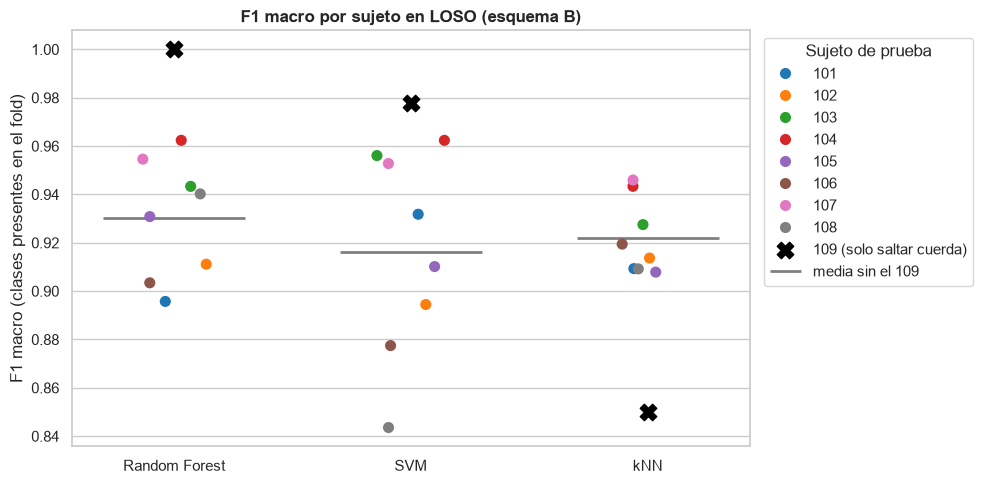

,media (9 folds),desv. (9 folds),media (sin 109),desv. (sin 109),peor sujeto
modelo,,,,,
Random Forest,0.938,0.033,0.930,0.024,101
SVM,0.923,0.045,0.916,0.042,108
kNN,0.914,0.028,0.922,0.015,109


In [22]:
por_fold = evaluacion.metricas_por_fold(principal)
por_sujeto = por_fold[por_fold["esquema"] == "B"].copy()
por_sujeto["modelo"] = por_sujeto["modelo"].map(NOMBRES)
por_sujeto["sujeto"] = por_sujeto["sujeto"].astype(int)
modelos_reales = [NOMBRES[m] for m in ["rf", "svm", "knn"]]

fig, ax = plt.subplots(figsize=(10, 5))
d = por_sujeto[por_sujeto["modelo"].isin(modelos_reales)]
sns.stripplot(data=d[d["sujeto"] != 109], x="modelo", y="f1_macro", order=modelos_reales,
              hue="sujeto", palette="tab10", size=8, jitter=0.15, ax=ax)
d109 = d[d["sujeto"] == 109]
ax.scatter([modelos_reales.index(m) for m in d109["modelo"]], d109["f1_macro"],
           marker="X", s=140, color="black", label="109 (solo saltar cuerda)", zorder=3)
medias = d[d["sujeto"] != 109].groupby("modelo")["f1_macro"].mean().reindex(modelos_reales)
ax.hlines(medias.values, np.arange(3) - 0.3, np.arange(3) + 0.3, color="gray", lw=2,
          label="media sin el 109")
ax.set_title("F1 macro por sujeto en LOSO (esquema B)")
ax.set_xlabel("")
ax.set_ylabel("F1 macro (clases presentes en el fold)")
ax.legend(title="Sujeto de prueba", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
guardar_figura(fig, "eval_01_f1_por_sujeto_loso", FIGURAS)
plt.show()

variab = pd.DataFrame({
    "media (9 folds)": d.groupby("modelo")["f1_macro"].mean(),
    "desv. (9 folds)": d.groupby("modelo")["f1_macro"].std(),
    "media (sin 109)": d[d["sujeto"] != 109].groupby("modelo")["f1_macro"].mean(),
    "desv. (sin 109)": d[d["sujeto"] != 109].groupby("modelo")["f1_macro"].std(),
    "peor sujeto": d.loc[d.groupby("modelo")["f1_macro"].idxmin()].set_index("modelo")["sujeto"],
}).reindex(modelos_reales).round(3)
variab.to_csv(RESULTADOS / "loso_variabilidad_con_sin_109.csv")
variab

El desempeño depende de quién sea el usuario nuevo. Con Random Forest el F1 va de 0.896 (sujeto 101) a 1.0 (sujeto 109), con una desviación de 0.033 entre los 9 folds y de 0.024 sin el 109.

El caso más claro es el **sujeto 108 con SVM** (F1 = 0.844, el peor de todos). El 108 es el único zurdo, así que lleva los sensores de muñeca y tobillo del lado izquierdo (§1). SVM clasifica como «acostado» 22 de sus 33 ventanas de saltar cuerda y 11 de las de correr: la orientación de los ejes queda espejeada respecto a los otros ocho sujetos y el modelo lo interpreta como otra postura. Random Forest es más robusto a esto (0.940 en el 108). **Este error solo puede aparecer en LOSO**: en A, el modelo siempre tiene en el entrenamiento ventanas del propio 108.

El fold del 109 (una sola clase, 23 ventanas) mueve bastante los resúmenes: sube la media de RF y SVM y baja la de kNN (0.85). Por eso la tabla reporta todo con y sin ese fold.

### 5.4 Análisis de errores

Comparamos las matrices de confusión, normalizadas por fila, del mejor modelo en B y de kNN, en los esquemas A y B. Cada fila muestra a qué se asignaron las ventanas de una actividad real; la diagonal es el porcentaje de aciertos.

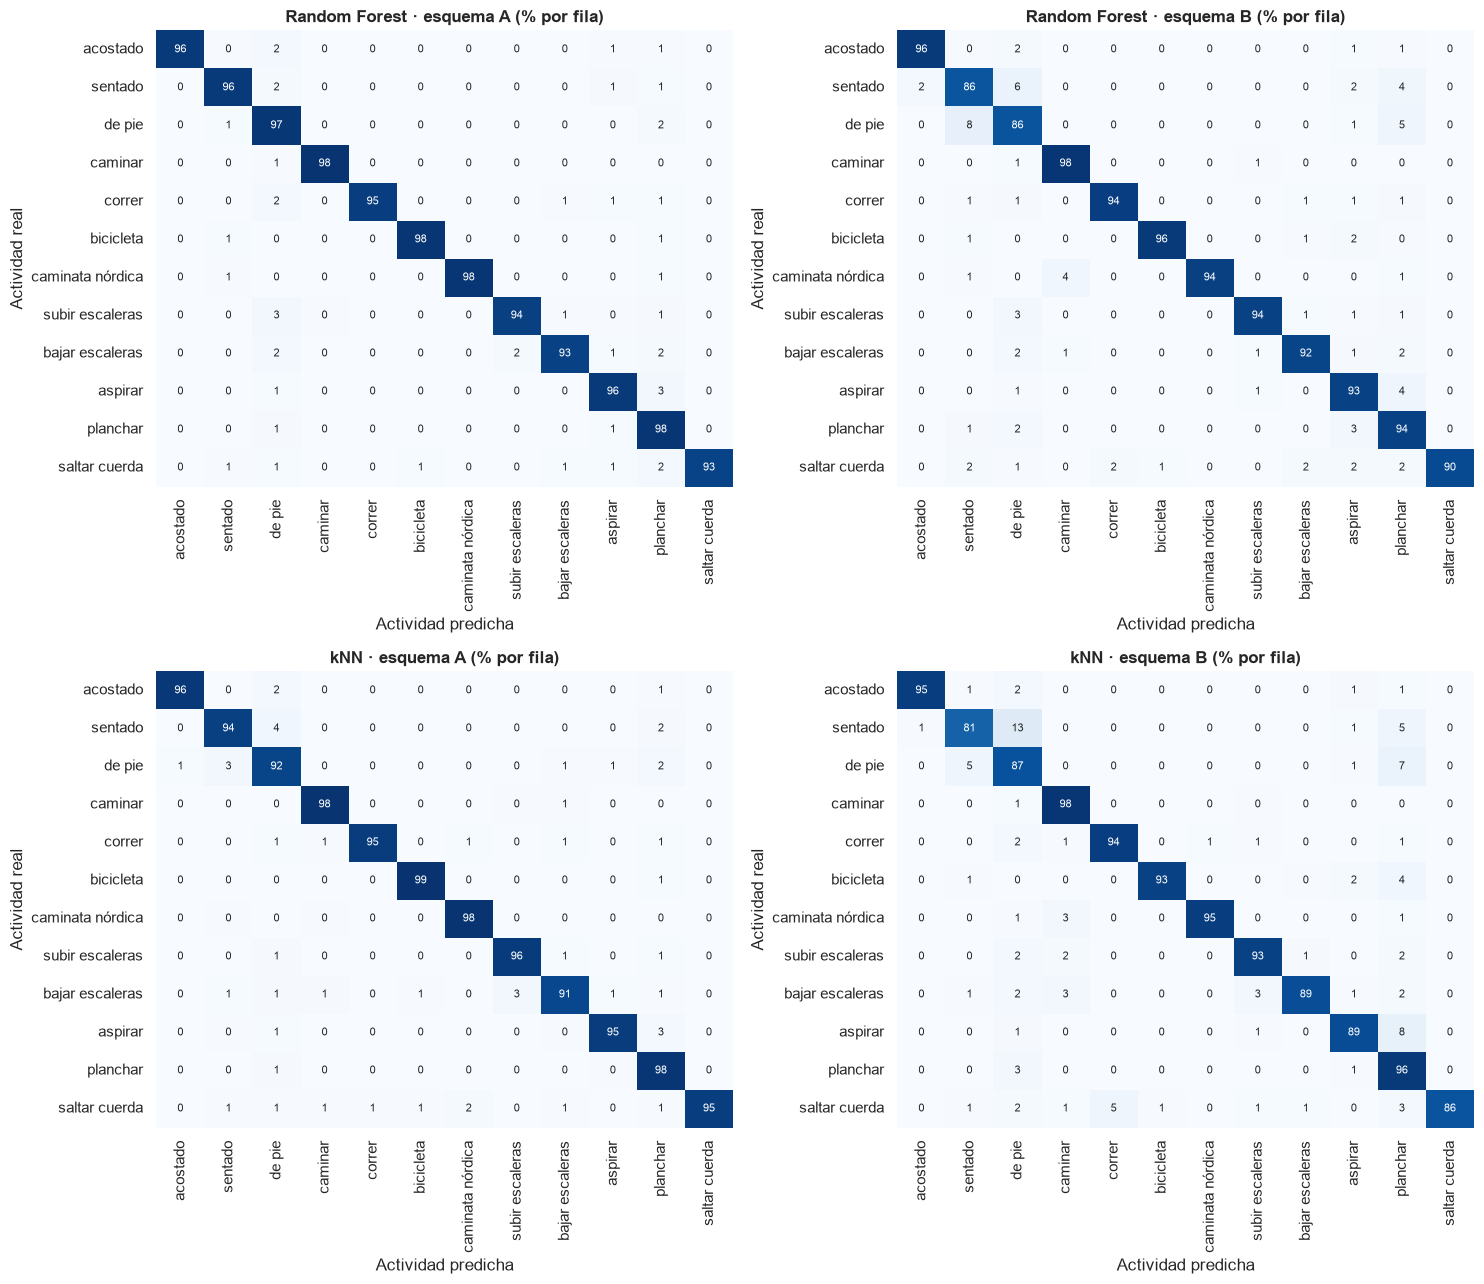

Mejor modelo en B: Random Forest

Pares más confundidos en B · Random Forest
   real predicha  proporción
 de pie  sentado       0.082
sentado   de pie       0.063
 de pie planchar       0.047
aspirar planchar       0.045
sentado planchar       0.041 

Pares más confundidos en B · kNN
         real predicha  proporción
      sentado   de pie       0.125
      aspirar planchar       0.079
       de pie planchar       0.067
      sentado planchar       0.051
saltar cuerda   correr       0.049 



In [23]:
MEJOR = resumen[resumen["esquema"] == "B"].set_index("modelo")["f1_fold_media"].idxmax()
CLAVE_MEJOR = {v: k for k, v in NOMBRES.items()}[MEJOR]

fig, ejes = plt.subplots(2, 2, figsize=(15, 13))
for fila, clave in enumerate([CLAVE_MEJOR, "knn"]):
    for col, esquema in enumerate(["A", "B"]):
        g = principal[(principal["modelo"] == clave) & (principal["esquema"] == esquema)]
        m = evaluacion.matriz_confusion(g, CLASES)
        sns.heatmap(m * 100, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100,
                    cbar=False, ax=ejes[fila, col], annot_kws={"fontsize": 8})
        ejes[fila, col].set_title(f"{NOMBRES[clave]} · esquema {esquema} (% por fila)")
        ejes[fila, col].set_xlabel("Actividad predicha")
        ejes[fila, col].set_ylabel("Actividad real")
plt.tight_layout()
guardar_figura(fig, "eval_02_matrices_confusion", FIGURAS)
plt.show()

print(f"Mejor modelo en B: {MEJOR}\n")
for clave in [CLAVE_MEJOR, "knn"]:
    g = principal[(principal["modelo"] == clave) & (principal["esquema"] == "B")]
    print(f"Pares más confundidos en B · {NOMBRES[clave]}")
    print(evaluacion.pares_mas_confundidos(evaluacion.matriz_confusion(g, CLASES))
          .round(3).to_string(index=False), "\n")

En A las matrices son casi diagonales (aciertos entre 91 % y 99 % por clase). En B aparecen errores con estructura:

- **Posturas y actividades de poco movimiento.** Los errores más frecuentes del mejor modelo (Random Forest) son *de pie ↔ sentado* (8 % y 6 %), *de pie → planchar*, *aspirar → planchar* y *sentado → planchar*. Estas actividades se distinguen sobre todo por la orientación del cuerpo y del brazo respecto a la gravedad, que cambia con la estatura, la postura y la forma de colocarse los sensores de cada persona. kNN tiene el mismo patrón, más marcado (*sentado → de pie*: 12.5 %).
- **Actividades de alto impacto (solo SVM).** *Correr → saltar cuerda* (21 %) y *saltar cuerda → acostado* (13 %), que vienen casi por completo del sujeto zurdo (108).

Estas son exactamente las clases candidatas para P2.

## 6. Respuesta a las preguntas de investigación

### 6.1 P1: ¿cuánto cae el F1 macro al pasar de partición aleatoria a partición por sujeto?

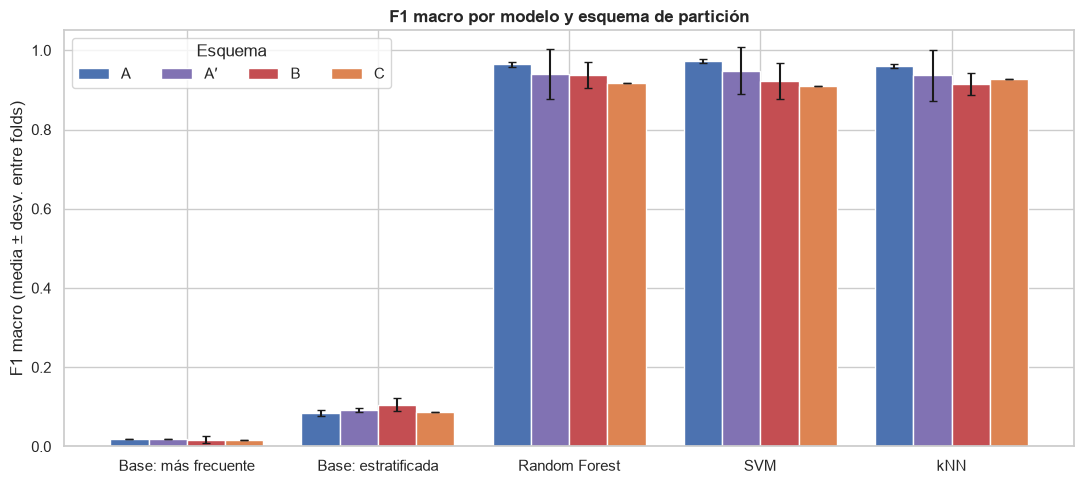

In [24]:
fig, ax = plt.subplots(figsize=(11, 5))
anchura = 0.2
colores_esq = {"A": "#4C72B0", "A′": "#8172B3", "B": "#C44E52", "C": "#DD8452"}
for i, esquema in enumerate(ORDEN_ESQUEMAS):
    r = resumen[resumen["esquema"] == esquema].set_index("modelo").reindex(
        [NOMBRES[m] for m in ORDEN_MODELOS])
    x = np.arange(len(r)) + (i - 1.5) * anchura
    ax.bar(x, r["f1_fold_media"], anchura, yerr=r["f1_fold_std"].fillna(0), capsize=3,
           label=esquema, color=colores_esq[esquema])
ax.set_xticks(np.arange(len(ORDEN_MODELOS)), [NOMBRES[m] for m in ORDEN_MODELOS])
ax.set_ylabel("F1 macro (media ± desv. entre folds)")
ax.set_ylim(0, 1.05)
ax.set_title("F1 macro por modelo y esquema de partición")
ax.legend(title="Esquema", ncols=4, loc="upper left")
plt.tight_layout()
guardar_figura(fig, "p1_01_f1_por_esquema", FIGURAS)
plt.show()

La tabla de descomposición separa la brecha total en sus dos partes (§0) y la compara con la desviación estándar del F1 entre sujetos en LOSO, que es el criterio de relevancia que fijamos en la propuesta.

In [25]:
f1 = resumen.pivot(index="modelo", columns="esquema", values="f1_fold_media")
desc = pd.DataFrame({
    "F1 A": f1["A"], "F1 A′": f1["A′"], "F1 B": f1["B"], "F1 C": f1["C"],
    "A − A′ (vecindad)": f1["A"] - f1["A′"],
    "A′ − B (personas)": f1["A′"] - f1["B"],
    "A − B (total)": f1["A"] - f1["B"],
    "desv. entre sujetos (B)": resumen[resumen["esquema"] == "B"].set_index("modelo")["f1_fold_std"],
}).loc[modelos_reales]
desc["% de la brecha por vecindad"] = desc["A − A′ (vecindad)"] / desc["A − B (total)"] * 100
desc["¿brecha > desv.?"] = np.where(desc["A − B (total)"] > desc["desv. entre sujetos (B)"], "sí", "no")
desc.round(3).to_csv(RESULTADOS / "p1_descomposicion.csv")
desc.round(3)

,F1 A,F1 A′,F1 B,F1 C,A − A′ (vecindad),A′ − B (personas),A − B (total),desv. entre sujetos (B),% de la brecha por vecindad,¿brecha > desv.?
modelo,,,,,,,,,,
Random Forest,0.964,0.940,0.938,0.916,0.025,0.002,0.026,0.033,93.679,no
SVM,0.972,0.948,0.923,0.909,0.025,0.025,0.049,0.045,49.627,sí
kNN,0.959,0.936,0.914,0.928,0.023,0.022,0.045,0.028,50.562,sí


#### ¿De dónde sale la dispersión de A′? Ventanas del centro contra ventanas de los extremos

A′ tiene una desviación de 0.06 porque sus folds 0 y 4, que prueban el **primer y el último 20 % de cada actividad**, dan un F1 de 0.86–0.91, mientras los bloques centrales dan 0.98–0.99. Para que la comparación sea justa, medimos el F1 de cada esquema **sobre las mismas ventanas**, separando las del centro de cada actividad (bloques 1–3) de las de los extremos (bloques 0 y 4):

In [26]:
from sklearn.metrics import f1_score  # F1 sobre un subconjunto de ventanas

# F1 macro de cada esquema sobre las mismas ventanas, separadas por su bloque temporal
bloque = particiones.asignar_bloques(meta)
zona = np.where(np.isin(bloque, [0, 4]), "extremos (bloques 0 y 4)", "centro (bloques 1–3)")
filas = []
for clave in ["rf", "svm", "knn"]:
    for esquema in ["A", "A′", "B"]:
        g = principal[(principal["modelo"] == clave) & (principal["esquema"] == esquema)]
        z = zona[g["indice"].to_numpy()]
        for nombre_zona in np.unique(zona):
            gg = g[z == nombre_zona]
            filas.append({"modelo": NOMBRES[clave], "zona": nombre_zona, "esquema": esquema,
                          "f1": f1_score(gg["y_real"], gg["y_pred"], labels=CLASES, average="macro")})
por_zona = pd.DataFrame(filas).pivot(index=["modelo", "zona"], columns="esquema", values="f1")[["A", "A′", "B"]]
por_zona["A − A′"] = por_zona["A"] - por_zona["A′"]
por_zona["A′ − B"] = por_zona["A′"] - por_zona["B"]
por_zona.round(3).to_csv(RESULTADOS / "p1_centro_contra_extremos.csv")
por_zona.round(3)

esquema                                     A     A′      B  A − A′  A′ − B
modelo        zona                                                         
Random Forest centro (bloques 1–3)      0.996  0.985  0.972   0.011   0.013
              extremos (bloques 0 y 4)  0.917  0.871  0.875   0.046  -0.004
SVM           centro (bloques 1–3)      0.997  0.989  0.941   0.008   0.049
              extremos (bloques 0 y 4)  0.935  0.885  0.852   0.050   0.033
kNN           centro (bloques 1–3)      0.991  0.983  0.966   0.008   0.017
              extremos (bloques 0 y 4)  0.912  0.866  0.860   0.045   0.007

Las ventanas de los extremos son más difíciles **en todos los esquemas**, también en A. Son el arranque y el final de cada actividad: la persona empieza a caminar, se acomoda para planchar o se detiene. Lo importante es dónde está la fuga:

- **En el centro** de las actividades, A − A′ es pequeño (≈ 0.01). Quitar la ventana gemela casi no cambia nada, porque las ventanas de en medio se parecen mucho a cualquier otra del mismo tramo, no solo a su vecina.
- **En los extremos**, A − A′ es de ≈ 0.05. En A, una ventana atípica del arranque tiene su vecina igual de atípica en el entrenamiento; en A′ esa vecina desaparece. La fuga por vecindad se concentra donde la señal es menos típica.
- En los extremos, A′ y B casi coinciden en Random Forest y kNN (RF: 0.871 contra 0.875). En el centro, en cambio, B queda por debajo de A′ (RF: 0.972 contra 0.985). La diferencia entre personas se nota sobre todo en la parte «estable» de la actividad.

#### Respuesta a P1

| Modelo | A − B (total) | A − A′ (vecindad) | A′ − B (personas) | Desv. entre sujetos | ¿Brecha > desv.? |
|---|---|---|---|---|---|
| Random Forest | 0.026 | 0.025 (94 %) | 0.002 | 0.033 (0.024 sin el 109) | **no** con el 109; apenas **sí** sin él |
| SVM | 0.049 | 0.025 (50 %) | 0.025 | 0.045 | sí, por poco |
| kNN | 0.045 | 0.023 (51 %) | 0.022 | 0.028 | **sí**, claramente |

**Sí hay fuga, pero es moderada.** Al pasar de la partición aleatoria (A) a la partición por sujeto (B), el F1 macro cae entre 0.026 (Random Forest) y 0.049 (SVM), es decir, de 3 a 5 puntos. Todos los modelos siguen por encima de 0.91 con personas nuevas.

**¿Es relevante?** El criterio que fijamos en la propuesta compara, dentro de cada modelo, la brecha A − B con la desviación del F1 entre sujetos en LOSO. Si la brecha es menor que esa desviación, cabe dentro de la diferencia normal entre una persona y otra.
- **kNN:** la brecha (0.045) supera con claridad su desviación (0.028). La fuga es relevante.
- **SVM:** la supera por poco (0.049 contra 0.045).
- **Random Forest:** queda en el límite. Con los 9 folds la brecha (0.026) es menor que la desviación (0.033); sin el fold del 109 la desviación baja a 0.024 y la brecha apenas la supera. La conclusión para RF depende de un solo sujeto, y por eso la reportamos como frágil.

**¿Qué parte es fuga y qué parte es diferencia entre personas?**
- **La parte por ventanas vecinas (A − A′) es casi idéntica en los tres modelos: 0.023–0.025.** Tiene sentido: viene del traslape de las ventanas, que es una propiedad de los datos y no del algoritmo. Esta sí es fuga.
- **La parte por personas nuevas (A′ − B) es lo que distingue a los modelos.** En Random Forest es casi nula (0.002), así que prácticamente toda su brecha es fuga. En SVM y kNN es ≈ 0.02, la mitad de su brecha: no es fuga, es que les cuesta más adaptarse a alguien que no vieron.
- ¿Por qué RF generaliza mejor a personas nuevas? kNN y SVM comparan ventanas con una distancia que usa los 196 atributos a la vez, así que cualquier diferencia propia de la persona aleja sus ventanas de las de los demás. Random Forest elige en cada corte los pocos atributos que mejor separan las actividades y puede ignorar el resto. Pusimos a prueba la versión más simple de esta idea en P3 (§6.3): quitar la temperatura y la frecuencia cardiaca, los atributos más ligados a la identidad del sujeto. **No mejoró a kNN ni a SVM**, así que su caída por personas no viene de esos atributos, sino de diferencias en las propias señales de movimiento, como la orientación de los sensores o ser zurdo, en el caso del 108.

**Hipótesis previa (kNN sería el más inflado): se cumple a medias.**
- **En magnitud, no.** La brecha de SVM (0.049) es mayor que la de kNN (0.045), y la parte que de verdad es fuga (A − A′) es la misma en los tres modelos.
- **En el mecanismo, sí.** Con la partición aleatoria, kNN elige `k = 1` en los 5 folds: copiar la etiqueta de la ventana más parecida, que casi siempre es la gemela traslapada. Con LOSO, donde la gemela ya no existe, elige `k = 5`. El propio modelo «descubre» que copiar a la vecina solo funciona cuando hay fuga, pero eso no lo hace más inflado que los demás.

#### ¿Qué me dio realmente?

- **¿La brecha es mayor que la variabilidad entre sujetos?** Para kNN sí; para SVM, apenas; para Random Forest depende de incluir o no al sujeto 109. La fuga existe en los tres modelos, pero su tamaño es parecido al de la diferencia que hay entre una persona y otra.
- **¿Qué parte viene de A − A′ y qué parte de A′ − B?** Unos 0.024 de F1 son fuga por ventanas vecinas en los tres modelos. El resto (0 en RF, ≈ 0.02 en SVM y kNN) es la dificultad real de generalizar a personas nuevas. La fuga se concentra en las ventanas del inicio y el final de cada actividad (A − A′ ≈ 0.05 ahí, contra ≈ 0.01 en el centro).
- **¿Coinciden las distintas formas de calcular el F1 macro?** En A, sí. En B difieren hasta 0.02 (§5.2), porque el F1 por fold trata a cada persona como una unidad y el agrupado a cada ventana; el fold del 109 (una sola clase) y los errores de SVM con el 108 pesan distinto en cada una. La brecha tiene el mismo signo y un tamaño parecido con ambas formas, pero la diferencia entre formas es del mismo orden que la brecha de RF, así que no conviene leer más allá del segundo decimal.
- **¿Qué no se puede concluir?**
  - Que el modelo con la mayor brecha es el que tiene más fuga. La mitad de la brecha de kNN y SVM es diferencia entre personas, no fuga.
  - Que un modelo es mejor que otro con personas nuevas. Las diferencias entre ellos en B (0.01–0.02) son menores que su desviación entre sujetos, y el ganador cambia según el esquema (SVM en A, RF en B, kNN en C).
  - Que la conclusión sobre RF es firme. Con 9 sujetos, uno solo (el 109) la cambia, y otro (el 108) explica casi todo el problema de SVM.
  - Que estas cifras valen fuera de este contexto. Son actividades guiadas en laboratorio, un solo dataset principal y ventanas fijas de 5.12 s con 50 % de traslape; con más traslape la fuga por vecindad sería mayor.
  - Que A′ elimina toda la fuga. A′ quita la ventana vecina, pero las ventanas del mismo tramo siguen siendo parecidas entre sí, así que A′ − B también puede contener algo de fuga «a distancia».

### 6.2 P2: ¿qué actividades son las más afectadas por la fuga?

Comparamos el F1 de cada actividad en A, A′ y B, calculado sobre las predicciones agrupadas de todos los folds. Así cada actividad tiene un solo F1 por esquema, aunque haya folds de LOSO en los que no aparece. La caída total A − B se descompone igual que en P1: vecindad (A − A′) y personas (A′ − B).

In [27]:
filas = []
for clave in ["rf", "svm", "knn"]:
    for esquema in ["A", "A′", "B"]:
        g = principal[(principal["modelo"] == clave) & (principal["esquema"] == esquema)]
        for actividad, valor in evaluacion.f1_por_clase(g, CLASES).items():
            filas.append({"modelo": NOMBRES[clave], "esquema": esquema,
                          "actividad": actividad, "f1": valor})
por_clase = pd.DataFrame(filas).pivot(index=["modelo", "actividad"], columns="esquema",
                                      values="f1")[["A", "A′", "B"]]
por_clase["caída A − B"] = por_clase["A"] - por_clase["B"]
por_clase["vecindad A − A′"] = por_clase["A"] - por_clase["A′"]
por_clase["personas A′ − B"] = por_clase["A′"] - por_clase["B"]

# Contexto del EDA: cuántas ventanas y cuántas personas tiene cada actividad
contexto = pd.DataFrame({"ventanas": meta["actividad"].value_counts(),
                         "sujetos": meta.groupby("actividad")["sujeto"].nunique()})
por_clase = por_clase.join(contexto, on="actividad")
por_clase.round(3).to_csv(RESULTADOS / "p2_f1_por_clase.csv")

# Ranking por caída en cada modelo
for modelo in modelos_reales:
    print(f"— {modelo}")
    print(por_clase.loc[modelo].sort_values("caída A − B", ascending=False)
          .round(3).to_string(), "\n")

— Random Forest
                      A     A′      B  caída A − B  vecindad A − A′  personas A′ − B  ventanas  sujetos
actividad                                                                                              
sentado           0.959  0.867  0.863        0.095            0.091            0.004       711        8
de pie            0.930  0.878  0.851        0.078            0.052            0.027       730        8
planchar          0.949  0.914  0.901        0.049            0.036            0.013       921        8
aspirar           0.953  0.917  0.909        0.043            0.036            0.007       673        8
caminata nórdica  0.988  0.988  0.967        0.021           -0.000            0.021       725        7
caminar           0.989  0.986  0.971        0.018            0.003            0.014       921        8
saltar cuerda     0.963  0.960  0.946        0.018            0.003            0.015       184        5
bajar escaleras   0.948  0.938  0.934        0.0

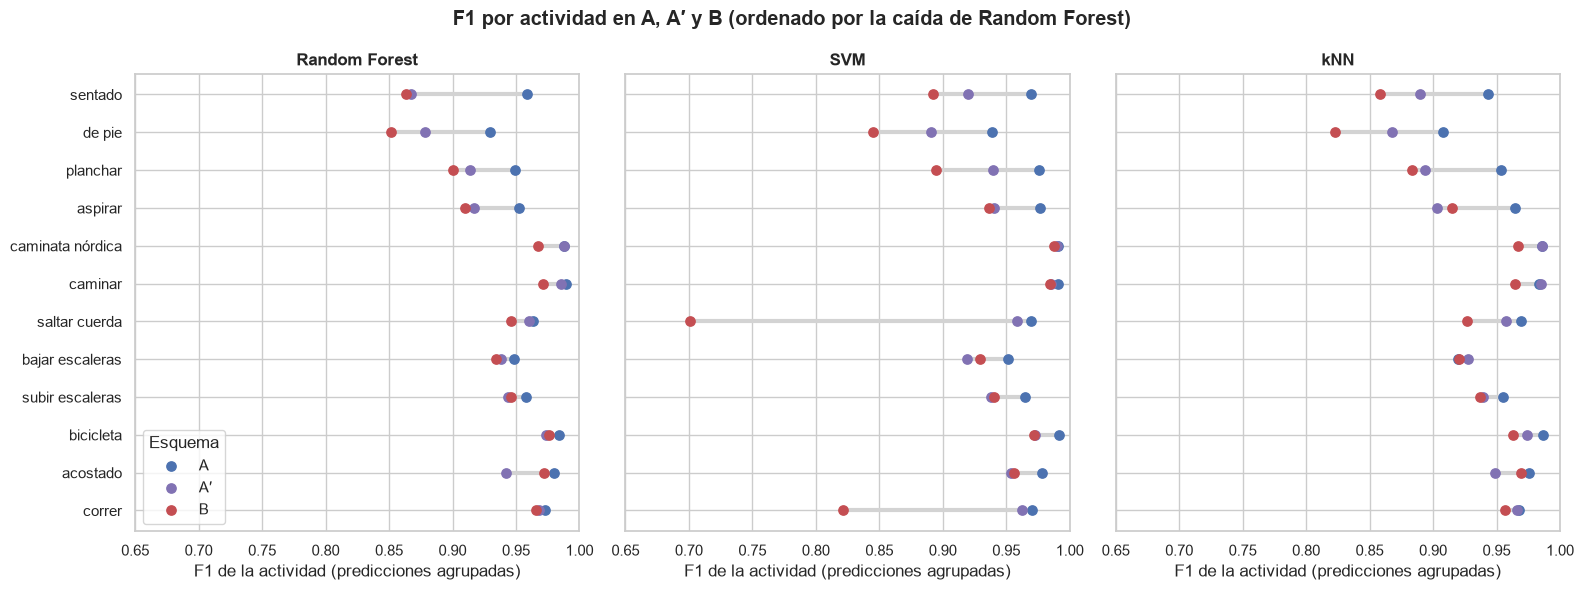

In [28]:
# Orden común para los tres paneles: caída de Random Forest, de mayor a menor
orden_p2 = por_clase.loc["Random Forest"].sort_values("caída A − B").index
fig, ejes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
for ax, modelo in zip(ejes, modelos_reales):
    t = por_clase.loc[modelo].reindex(orden_p2)
    yy = np.arange(len(t))
    ax.hlines(yy, t[["A", "A′", "B"]].min(axis=1), t[["A", "A′", "B"]].max(axis=1),
              color="lightgray", lw=3, zorder=1)
    for esquema in ["A", "A′", "B"]:
        ax.scatter(t[esquema], yy, color=colores_esq[esquema], s=45, zorder=2, label=esquema)
    ax.set_yticks(yy, t.index)
    ax.set_xlim(0.65, 1.0)
    ax.set_title(modelo)
    ax.set_xlabel("F1 de la actividad (predicciones agrupadas)")
ejes[0].legend(title="Esquema", loc="lower left")
fig.suptitle("F1 por actividad en A, A′ y B (ordenado por la caída de Random Forest)",
             fontweight="bold")
plt.tight_layout()
guardar_figura(fig, "p2_01_f1_por_actividad", FIGURAS)
plt.show()

Cada fila une el F1 de una actividad en los tres esquemas; cuanto más larga la barra gris, más le afecta pasar de A a B. Las actividades de arriba son las que más caen con Random Forest.

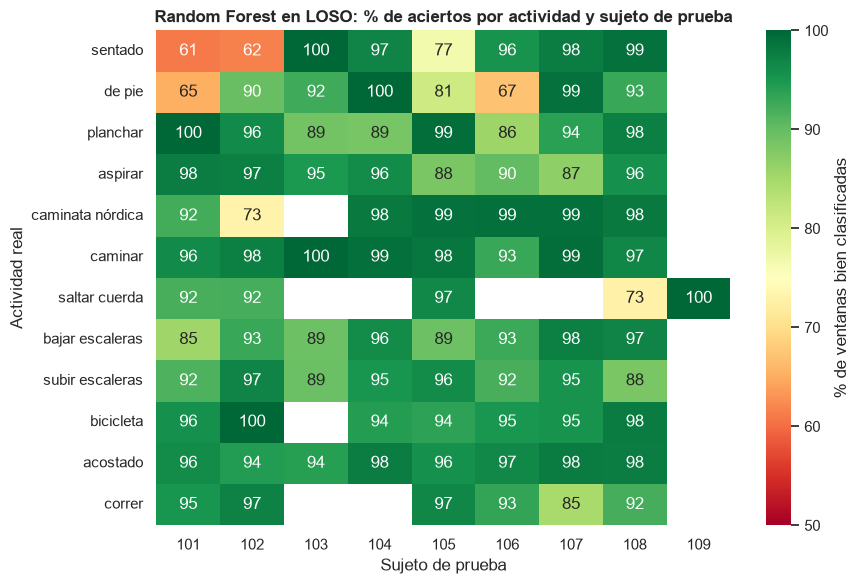

In [29]:
# ¿En qué personas fallan las actividades más afectadas? Aciertos (recall) de RF en B
g = principal[(principal["modelo"] == "rf") & (principal["esquema"] == "B")]
aciertos = (g.assign(acierto=g["y_real"] == g["y_pred"])
            .groupby(["y_real", "sujeto"])["acierto"].mean().unstack()
            .reindex(orden_p2[::-1]))
fig, ax = plt.subplots(figsize=(9, 6))
sns.heatmap(aciertos * 100, annot=True, fmt=".0f", cmap="RdYlGn", vmin=50, vmax=100,
            cbar_kws={"label": "% de ventanas bien clasificadas"}, ax=ax)
ax.grid(False)  # sin cuadrícula: las celdas vacías (actividad no realizada) quedan en blanco
ax.set_title("Random Forest en LOSO: % de aciertos por actividad y sujeto de prueba")
ax.set_xlabel("Sujeto de prueba")
ax.set_ylabel("Actividad real")
plt.tight_layout()
guardar_figura(fig, "p2_02_aciertos_por_sujeto_rf", FIGURAS)
plt.show()

Las celdas en blanco son actividades que ese sujeto no realizó. Las caídas de *sentado* y *de pie* no se reparten entre todos: vienen de pocos sujetos (101, 102 y 105 en *sentado*; 101, 105 y 106 en *de pie*), que el modelo confunde entre sí y con *planchar* (§5.4).

#### Respuesta a P2

**Las actividades más afectadas son las de poco movimiento: sentado, de pie, planchar y aspirar.** Son las cuatro primeras del ranking en Random Forest y kNN; en SVM ocupan los lugares 3 a 6, detrás de saltar cuerda y correr. Con RF, *sentado* cae 0.095 y *de pie* 0.078, contra menos de 0.02 en caminar, correr o bicicleta.

**En esas actividades, casi toda la caída es fuga por vecindad.** En *sentado* con RF, 0.091 de los 0.095 se pierden ya al pasar de A a A′, antes de cambiar de persona. La tabla de similitud del EDA (§3.4, `results/similitud_ventanas_por_actividad.csv`) explica por qué:

| Actividad | Ventana consecutiva | Otra ventana del mismo sujeto | Ventana de otro sujeto |
|---|---|---|---|
| sentado | 7.0 | 11.2 | 12.3 |
| de pie | 5.5 | 8.2 | 9.7 |
| caminar | 3.4 | 4.6 | 8.2 |
| correr | 5.1 | 8.3 | 22.2 |

En *sentado*, quitando la ventana gemela, el resto de las ventanas del mismo sujeto ya está casi tan lejos (11.2) como las de otra persona (12.3): a lo largo de varios minutos sentada, la persona se acomoda y cambia ligeramente de postura. La gemela es la única referencia realmente cercana, y en A el modelo se apoya en ella. Sin la gemela tiene que separar *sentado* de *de pie* por la orientación del tronco y los muslos respecto a la gravedad, una diferencia pequeña que además depende de cómo se sienta o se para cada quien. En *caminar* pasa lo contrario: las demás ventanas del mismo sujeto siguen muy cerca (4.6), así que perder a la gemela casi no importa.

**En las actividades dinámicas (caminar, correr, bicicleta, caminata nórdica) la fuga casi no existe.** Su caída es de 0.01–0.02 y viene de la parte por personas, no de la vecindad. Tienen un patrón periódico tan característico que se reconoce en cualquier ventana y en cualquier persona.

**Saltar cuerda, la clase con menos personas (5), depende del modelo.** Con RF y kNN cae poco (0.02–0.04). Con SVM cae 0.27, y casi todo es por personas (A′ − B = 0.26): son los errores con el sujeto zurdo 108 (§5.3). Con tan pocos sujetos, una sola persona atípica en la prueba basta para hundir una clase. Correr (6 sujetos) muestra lo mismo con SVM (0.15). El desbalance de ventanas, en cambio, no explica la caída: caminar y planchar tienen el mismo número de ventanas (921) y caen muy distinto.

**Lo que no se puede concluir:** que sentado y de pie sean «intrínsecamente» difíciles para cualquier usuario. Sus caídas vienen de 2 o 3 sujetos, así que con 9 personas no sabemos qué tan frecuente es ese caso en una población mayor.

### 6.3 P3: ¿qué características se mantienen útiles entre sujetos?

Respondemos con cuatro análisis complementarios. Todos usan Random Forest, el mejor modelo en B, con los hiperparámetros que eligió la búsqueda anidada de la Fase 3 **en cada fold**, así que no se vuelven a elegir hiperparámetros con datos de prueba.

1. **Importancia por permutación.** Se desordena al azar un atributo en los datos de **prueba** y se mide cuánto baja el F1. Si baja mucho, el modelo dependía de ese atributo. Se calcula sobre el sujeto de prueba de cada fold LOSO y, como contraste, sobre la prueba de cada fold de A. Comparar los dos rankings dice qué atributos pierden importancia cuando la persona es nueva.
   - Los atributos de un mismo sensor están muy correlacionados. Si se desordena solo uno, el modelo lo sustituye con sus «hermanos» y la importancia individual sale casi nula. Por eso también se permutan **grupos completos** (por ejemplo, todo el acelerómetro del tobillo a la vez), que es la lectura principal.
2. **Información mutua**: un contraste univariado, calculado solo con el entrenamiento de cada fold.
3. **RFE**: eliminación recursiva de 10 en 10 atributos dentro de cada fold LOSO, para encontrar el subconjunto mínimo que conserva ≥ 95 % del F1.
4. **PCA** dentro del pipeline, como contraste de reducción de dimensión.

El fold del sujeto 109 se excluye de los promedios de importancia. Tiene 23 ventanas de una sola clase y el modelo las acierta todas aunque se desordene cualquier sensor, así que todas sus importancias valen 0 y solo diluirían el promedio.

Igual que en la Fase 3, estos análisis se calculan con un script aparte (`python -m src.experimentos_p3`, ≈ 5 min) que guarda sus resultados en `results/fase4/`, y aquí se cargan.

In [30]:
from src import experimentos_p3  # noqa: E402

CARPETA_FASE4 = RESULTADOS / "fase4"
RECALCULAR_P3 = False  # True para recalcular los análisis de P3 desde el notebook
if RECALCULAR_P3 or not (CARPETA_FASE4 / "sin_persona_B.csv").exists():
    experimentos_p3.ejecutar(RAIZ, forzar=RECALCULAR_P3)

f4 = {n: pd.read_csv(CARPETA_FASE4 / f"{n}.csv") for n in [
    "perm_grupos_A", "perm_grupos_B", "perm_atributos_A", "perm_atributos_B",
    "info_mutua_B", "rfe_curva_B", "rfe_ranking_B", "pca_B", "sin_persona_B"]}
print({n: d.shape for n, d in f4.items()})

{'perm_grupos_A': (40, 6), 'perm_grupos_B': (72, 6), 'perm_atributos_A': (980, 6), 'perm_atributos_B': (1764, 6), 'info_mutua_B': (1764, 5), 'rfe_curva_B': (180, 4), 'rfe_ranking_B': (1764, 4), 'pca_B': (18, 5), 'sin_persona_B': (54, 5)}


#### Importancia por grupo de sensores

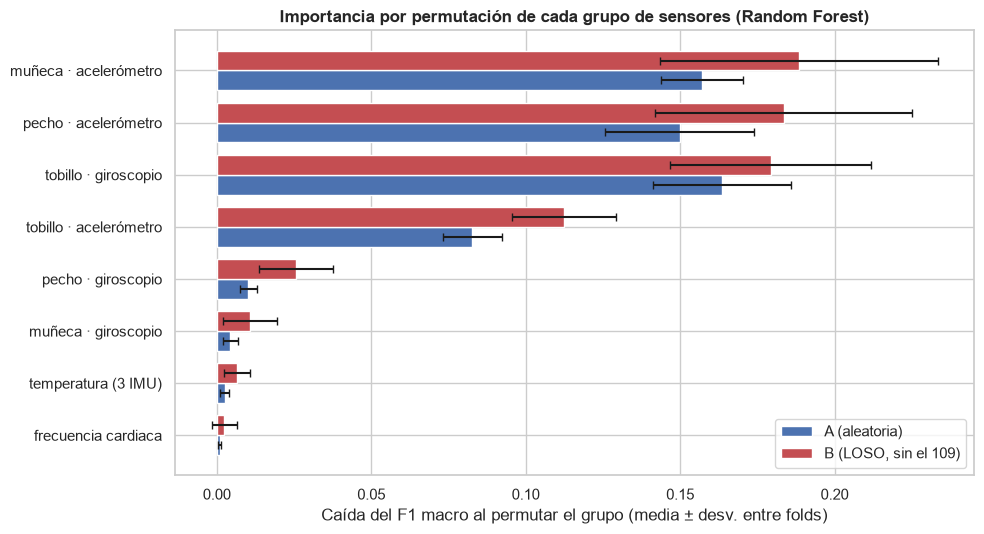

A             B       
                         mean    std   mean    std
grupo                                             
frecuencia cardiaca     0.001  0.000  0.002  0.004
temperatura (3 IMU)     0.003  0.002  0.006  0.004
muñeca · giroscopio     0.004  0.002  0.011  0.009
pecho · giroscopio      0.010  0.003  0.026  0.012
tobillo · acelerómetro  0.083  0.010  0.112  0.017
tobillo · giroscopio    0.164  0.022  0.179  0.033
pecho · acelerómetro    0.150  0.024  0.184  0.042
muñeca · acelerómetro   0.157  0.013  0.188  0.045

In [31]:
def resumen_importancia(df, clave):
    """Media y desviación entre folds de la importancia, sin el fold del sujeto 109."""
    df = df[df["sujeto"] != 109]
    return df.groupby(clave)["importancia"].agg(["mean", "std"])

NOMBRE_GRUPO = {"muneca_acc": "muñeca · acelerómetro", "muneca_gyro": "muñeca · giroscopio",
                "pecho_acc": "pecho · acelerómetro", "pecho_gyro": "pecho · giroscopio",
                "tobillo_acc": "tobillo · acelerómetro", "tobillo_gyro": "tobillo · giroscopio",
                "temperatura": "temperatura (3 IMU)", "frecuencia cardiaca": "frecuencia cardiaca"}
imp_grupos = pd.concat({"A": resumen_importancia(f4["perm_grupos_A"], "grupo"),
                        "B": resumen_importancia(f4["perm_grupos_B"], "grupo")}, axis=1)
imp_grupos.index = imp_grupos.index.map(NOMBRE_GRUPO)
imp_grupos = imp_grupos.sort_values(("B", "mean"))
imp_grupos.round(4).to_csv(RESULTADOS / "p3_importancia_grupos.csv")

fig, ax = plt.subplots(figsize=(10, 5.5))
yy = np.arange(len(imp_grupos))
for i, esquema in enumerate(["A", "B"]):
    ax.barh(yy + (i - 0.5) * 0.38, imp_grupos[(esquema, "mean")], 0.38,
            xerr=imp_grupos[(esquema, "std")], capsize=3, color=colores_esq[esquema],
            label=f"{esquema} ({'aleatoria' if esquema == 'A' else 'LOSO, sin el 109'})")
ax.set_yticks(yy, imp_grupos.index)
ax.set_xlabel("Caída del F1 macro al permutar el grupo (media ± desv. entre folds)")
ax.set_title("Importancia por permutación de cada grupo de sensores (Random Forest)")
ax.legend(loc="lower right")
plt.tight_layout()
guardar_figura(fig, "p3_01_importancia_grupos", FIGURAS)
plt.show()
imp_grupos.round(3)

Cada barra es cuánto baja el F1 si se «apaga» ese sensor desordenando sus atributos.

- **Los cuatro grupos útiles son los mismos en A y en B:** acelerómetros de muñeca, pecho y tobillo, y giroscopio del tobillo. Cada uno, al permutarlo, baja el F1 entre 0.11 y 0.19 en LOSO. El giroscopio del pecho y el de la muñeca aportan poco (< 0.03), y la temperatura y la frecuencia cardiaca casi nada (< 0.01).
- **En B todos los grupos importan más que en A.** En A, si se apaga un sensor, los demás todavía bastan para reconocer la ventana gemela; con una persona nueva no hay gemela, y perder un sensor duele más.
- **Cambia el orden.** En A el más importante es el giroscopio del tobillo; en LOSO, el acelerómetro de la muñeca. La desviación entre folds también crece en B (hasta 0.045): qué tanto importa un sensor depende de la persona.

#### Importancia de cada atributo: A contra B

Correlación de Spearman entre los rankings de A y B: 0.48
Atributos con importancia ≤ 0 en B: 37 de 196


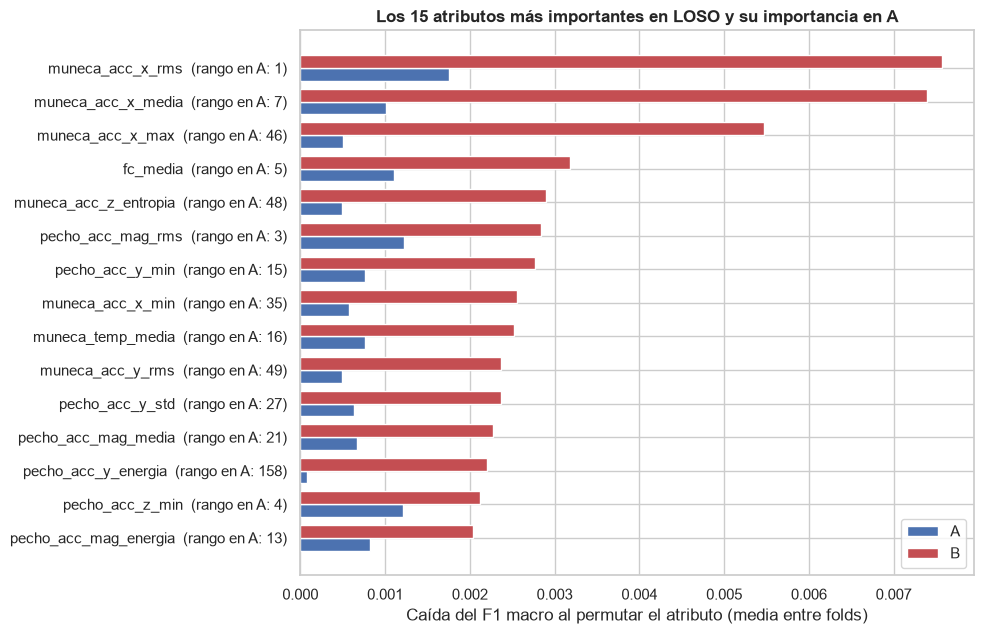


Atributos que más pierden importancia en LOSO respecto a A:


A       B rango     
                          mean    mean     A    B
atributo                                         
pecho_acc_z_media       0.0010  0.0002     6  130
tobillo_acc_x_media     0.0006 -0.0002    31  173
tobillo_gyro_y_energia  0.0003 -0.0004    89  192
pecho_gyro_mag_std      0.0004 -0.0003    58  187
pecho_gyro_y_max        0.0004 -0.0003    60  188
tobillo_gyro_mag_rms    0.0002 -0.0005   118  195
tobillo_gyro_x_rms      0.0001 -0.0006   147  196
tobillo_acc_mag_media   0.0003 -0.0004    79  190

In [32]:
imp_atr = pd.concat({"A": resumen_importancia(f4["perm_atributos_A"], "atributo"),
                     "B": resumen_importancia(f4["perm_atributos_B"], "atributo")}, axis=1)
imp_atr[("rango", "A")] = imp_atr[("A", "mean")].rank(ascending=False).astype(int)
imp_atr[("rango", "B")] = imp_atr[("B", "mean")].rank(ascending=False).astype(int)
imp_atr = imp_atr.sort_values(("B", "mean"), ascending=False)
imp_atr.round(4).to_csv(RESULTADOS / "p3_importancia_atributos.csv")

rho = imp_atr[("A", "mean")].corr(imp_atr[("B", "mean")], method="spearman")
print(f"Correlación de Spearman entre los rankings de A y B: {rho:.2f}")
print(f"Atributos con importancia ≤ 0 en B: {(imp_atr[('B', 'mean')] <= 0).sum()} de {len(imp_atr)}")

top = imp_atr.head(15)[::-1]
fig, ax = plt.subplots(figsize=(10, 6.5))
yy = np.arange(len(top))
for i, esquema in enumerate(["A", "B"]):
    ax.barh(yy + (i - 0.5) * 0.38, top[(esquema, "mean")], 0.38, color=colores_esq[esquema],
            label=esquema)
ax.set_yticks(yy, [f"{n}  (rango en A: {r})" for n, r in zip(top.index, top[("rango", "A")])])
ax.set_xlabel("Caída del F1 macro al permutar el atributo (media entre folds)")
ax.set_title("Los 15 atributos más importantes en LOSO y su importancia en A")
ax.legend(loc="lower right")
plt.tight_layout()
guardar_figura(fig, "p3_02_importancia_atributos", FIGURAS)
plt.show()

print("\nAtributos que más pierden importancia en LOSO respecto a A:")
perdida = imp_atr[("A", "mean")] - imp_atr[("B", "mean")]
imp_atr.loc[perdida.sort_values(ascending=False).index[:8],
            [("A", "mean"), ("B", "mean"), ("rango", "A"), ("rango", "B")]].round(4)

Atributo por atributo, las importancias son muy pequeñas (≤ 0.008), como anticipamos: casi todos tienen un sustituto correlacionado. Aun así, hay patrones:

- **Los rankings de A y B se parecen solo a medias** (Spearman ≈ 0.48). Cambia qué atributo concreto se usa, aunque los sensores importantes sean los mismos.
- **En LOSO destacan los atributos de orientación e intensidad de la muñeca y el pecho**: `muneca_acc_x_rms`, `muneca_acc_x_media` y `pecho_acc_mag_rms`. La media del acelerómetro indica cómo está inclinado el sensor respecto a la gravedad, que es lo que separa *sentado*, *de pie* y *planchar*.
- **Los que más pierden importancia** son, sobre todo, atributos del giroscopio del tobillo y del pecho y algunas medias de orientación (por ejemplo `pecho_acc_z_media`, del lugar 6 al 130).
- `fc_media` y `muneca_temp_media` entran al top 15 de LOSO, pero con caídas de ≈ 0.003. Como grupo, temperatura y frecuencia cardiaca valen menos de 0.01, contra 0.11–0.19 de cada acelerómetro.
- Unos 37 atributos tienen importancia ≤ 0 en LOSO: desordenarlos no empeora, y a veces mejora, el resultado con personas nuevas.

**Cuidado con la lectura individual.** `pecho_acc_z_media` y `tobillo_acc_x_media` caen al fondo del ranking de permutación en LOSO, pero más abajo veremos que RFE los conserva en los 9 folds. No es una contradicción. RFE mide cuánto usa el modelo un atributo al entrenar; la permutación mide cuánto se pierde al desordenarlo en la prueba. Si otro atributo lleva casi la misma información (la media del pecho en z y la del pecho en magnitud, por ejemplo), el modelo usa uno de los dos, pero al desordenarlo el otro lo sustituye y la caída sale casi nula. Por eso la conclusión de P3 se apoya en los grupos, no en atributos sueltos.

#### Información mutua: ¿qué atributos dicen más de la actividad y cuáles delatan a la persona?

La información mutua mide cuánto reduce un atributo, por sí solo, la incertidumbre sobre otra variable. La calculamos con el entrenamiento de cada fold LOSO contra dos variables: la **actividad** (lo que queremos predecir) y el **sujeto** (lo que no queremos que el modelo aprenda). Un atributo con mucha información sobre el sujeto y poca sobre la actividad es candidato a no generalizar.

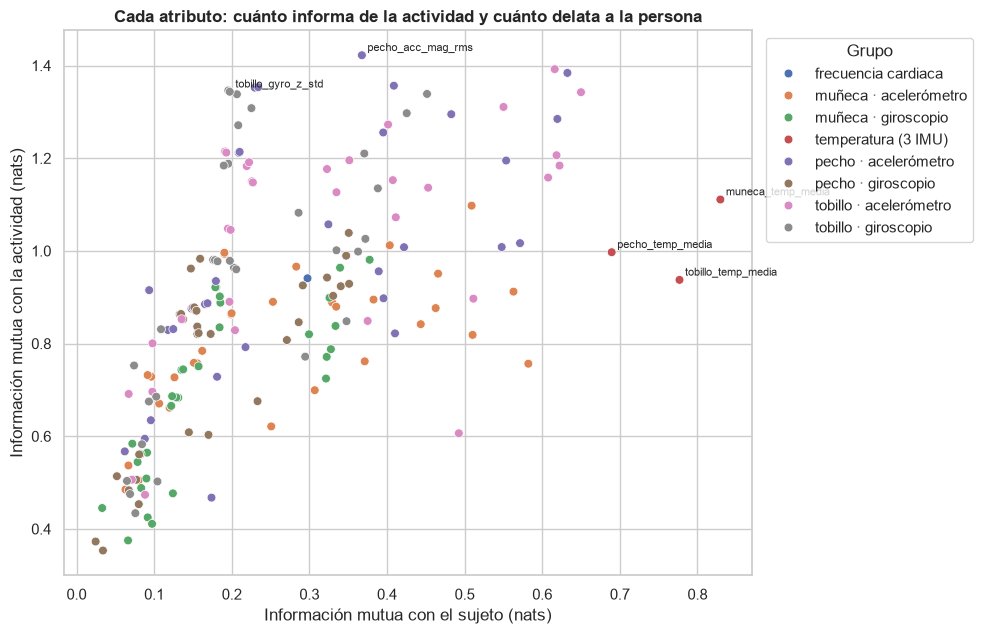

Spearman entre información mutua con la actividad e importancia por permutación en B: 0.08


,mi_actividad,mi_sujeto,grupo
atributo,,,
pecho_acc_mag_rms,1.422,0.368,pecho · acelerómetro
tobillo_acc_x_max,1.392,0.616,tobillo · acelerómetro
pecho_acc_y_max,1.384,0.632,pecho · acelerómetro
pecho_acc_mag_max,1.357,0.409,pecho · acelerómetro
pecho_acc_mag_std,1.353,0.234,pecho · acelerómetro
pecho_acc_mag_energia,1.352,0.230,pecho · acelerómetro
tobillo_gyro_z_energia,1.346,0.196,tobillo · giroscopio
tobillo_gyro_z_std,1.343,0.197,tobillo · giroscopio


In [33]:
im = f4["info_mutua_B"].groupby("atributo")[["mi_actividad", "mi_sujeto"]].mean()
im["grupo"] = [NOMBRE_GRUPO[experimentos_p3.grupo_de(a)] for a in im.index]
im.round(3).to_csv(RESULTADOS / "p3_informacion_mutua.csv")

fig, ax = plt.subplots(figsize=(10, 6.5))
sns.scatterplot(data=im, x="mi_sujeto", y="mi_actividad", hue="grupo", s=40, ax=ax)
for a in ["pecho_acc_mag_rms", "tobillo_gyro_z_std", "muneca_temp_media", "pecho_temp_media",
          "tobillo_temp_media"]:
    ax.annotate(a, (im.loc[a, "mi_sujeto"], im.loc[a, "mi_actividad"]), fontsize=8,
                xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("Información mutua con el sujeto (nats)")
ax.set_ylabel("Información mutua con la actividad (nats)")
ax.set_title("Cada atributo: cuánto informa de la actividad y cuánto delata a la persona")
ax.legend(title="Grupo", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
guardar_figura(fig, "p3_03_informacion_mutua", FIGURAS)
plt.show()

rho_im = im["mi_actividad"].corr(imp_atr[("B", "mean")], method="spearman")
print(f"Spearman entre información mutua con la actividad e importancia por permutación en B: {rho_im:.2f}")
im.sort_values("mi_actividad", ascending=False).head(8).round(3)

- **Los atributos con más información sobre la actividad** son de intensidad del pecho (`pecho_acc_mag_rms`, `_std`, `_energia`) y del giroscopio del tobillo en el eje z (`tobillo_gyro_z_*`), el eje en el que gira la pierna al dar un paso. Muchos de ellos están arriba a la izquierda en la gráfica: informan mucho de la actividad y poco del sujeto. Los máximos del acelerómetro del tobillo y del pecho, en cambio, informan igual de la actividad pero delatan bastante más a la persona.
- **Los que más delatan a la persona** son las tres temperaturas (a la derecha de la gráfica). La temperatura de la piel cambia poco dentro de una sesión y mucho entre personas.
- **La información mutua casi no coincide con la importancia por permutación** (Spearman ≈ 0.08). Es lo esperado: la información mutua mira cada atributo aislado, y Random Forest combina atributos y descarta los redundantes. Es un contraste útil, pero no sustituye a la permutación.

#### Comprobación: ¿quitar los atributos que delatan a la persona ayuda a generalizar?

En P1 propusimos que kNN y SVM pierden más con personas nuevas porque su distancia usa todos los atributos, incluidos los que identifican al sujeto. La prueba más directa es entrenar los tres modelos en LOSO sin la temperatura ni la frecuencia cardiaca, con los mismos hiperparámetros de la Fase 3.

In [34]:
sp = f4["sin_persona_B"].copy()
sp["modelo"] = sp["modelo"].map(NOMBRES)
tabla_sp = pd.concat({
    "9 folds": sp.pivot_table(index="modelo", columns="variante", values="f1", aggfunc="mean"),
    "sin el 109": sp[sp["sujeto"] != 109].pivot_table(index="modelo", columns="variante",
                                                     values="f1", aggfunc="mean"),
}, axis=1).loc[modelos_reales]
for k in ["9 folds", "sin el 109"]:
    tabla_sp[(k, "diferencia")] = tabla_sp[(k, "sin temperatura ni FC")] - tabla_sp[(k, "todos")]
tabla_sp = tabla_sp[[(k, c) for k in ["9 folds", "sin el 109"]
                     for c in ["todos", "sin temperatura ni FC", "diferencia"]]]
tabla_sp.round(3).to_csv(RESULTADOS / "p3_sin_atributos_de_persona.csv")
tabla_sp.round(3)

9 folds                                  sin el 109  \
variante        todos sin temperatura ni FC diferencia      todos   
modelo                                                              
Random Forest   0.938                 0.937     -0.001      0.930   
SVM             0.923                 0.918     -0.005      0.916   
kNN             0.914                 0.902     -0.012      0.922   

                                                
variante      sin temperatura ni FC diferencia  
modelo                                          
Random Forest                 0.929     -0.001  
SVM                           0.911     -0.005  
kNN                           0.916     -0.006

**La explicación no se sostiene.** Sin temperatura ni frecuencia cardiaca, ningún modelo mejora en LOSO: Random Forest queda igual y kNN y SVM bajan un poco. La columna «todos» reproduce exactamente los F1 de la Fase 3, lo que confirma que los resultados son consistentes. Así que la caída por personas de kNN y SVM no se debe a estos atributos, sino a diferencias entre personas en las propias señales de movimiento. Es un resultado negativo, pero útil: descarta la explicación más simple.

#### Subconjunto mínimo de atributos (RFE dentro de cada fold LOSO)

En cada fold, RFE entrena un Random Forest con el entrenamiento, quita los 10 atributos menos importantes, vuelve a entrenar, y así hasta quedarse con 6. Para cada tamaño evaluamos un Random Forest con esos atributos en el sujeto de prueba. El ranking se aprende sin ver al sujeto de prueba, así que la curva no tiene fuga.

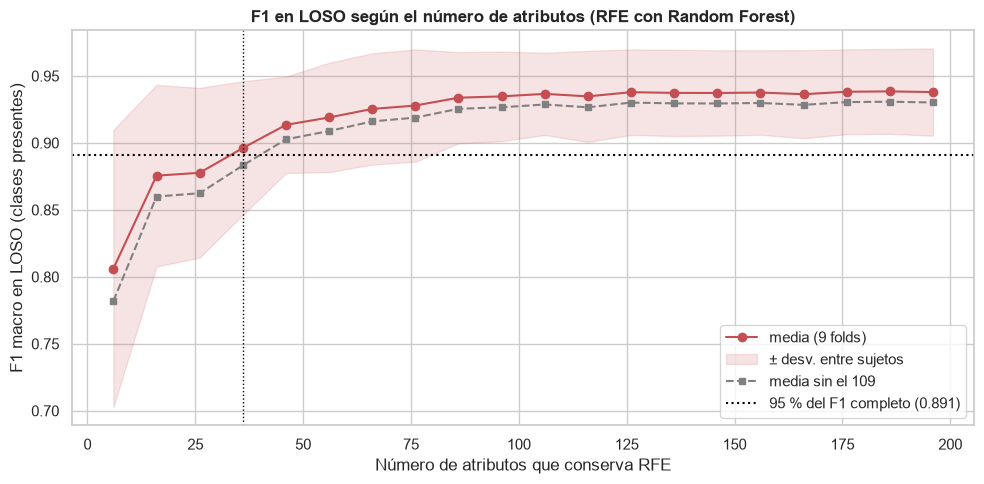

F1 con los 196 atributos: 0.938
Mínimo con ≥ 95 %: 36 atributos (F1 = 0.896); sin el 109: 46
Mínimo con ≥ 99 %: 86 atributos (F1 = 0.934)


In [35]:
curva = f4["rfe_curva_B"]
cur = curva.groupby("n_atributos")["f1"].agg(["mean", "std"])
cur["sin 109"] = curva[curva["sujeto"] != 109].groupby("n_atributos")["f1"].mean()
completo = cur.loc[cur.index.max(), "mean"]
umbral = 0.95 * completo
k_min = int(cur[cur["mean"] >= umbral].index.min())
k_99 = int(cur[cur["mean"] >= 0.99 * completo].index.min())
k_min_sin109 = int(cur[cur["sin 109"] >= 0.95 * cur.loc[cur.index.max(), "sin 109"]].index.min())
cur.round(4).to_csv(RESULTADOS / "p3_curva_rfe.csv")

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(cur.index, cur["mean"], "o-", color=colores_esq["B"], label="media (9 folds)")
ax.fill_between(cur.index, cur["mean"] - cur["std"], cur["mean"] + cur["std"],
                color=colores_esq["B"], alpha=0.15, label="± desv. entre sujetos")
ax.plot(cur.index, cur["sin 109"], "s--", color="gray", ms=4, label="media sin el 109")
ax.axhline(umbral, color="black", ls=":", label=f"95 % del F1 completo ({umbral:.3f})")
ax.axvline(k_min, color="black", ls=":", lw=1)
ax.set_xlabel("Número de atributos que conserva RFE")
ax.set_ylabel("F1 macro en LOSO (clases presentes)")
ax.set_title("F1 en LOSO según el número de atributos (RFE con Random Forest)")
ax.legend(loc="lower right")
plt.tight_layout()
guardar_figura(fig, "p3_04_curva_rfe", FIGURAS)
plt.show()

print(f"F1 con los 196 atributos: {completo:.3f}")
print(f"Mínimo con ≥ 95 %: {k_min} atributos (F1 = {cur.loc[k_min, 'mean']:.3f}); "
      f"sin el 109: {k_min_sin109}")
print(f"Mínimo con ≥ 99 %: {k_99} atributos (F1 = {cur.loc[k_99, 'mean']:.3f})")

In [36]:
# ¿Qué atributos forman el subconjunto mínimo? Cada fold elige el suyo; contamos en cuántos
# de los 9 folds aparece cada atributo entre los k_min mejores
rk = f4["rfe_ranking_B"]
corte = (k_min - experimentos_p3.MINIMO_RFE) // experimentos_p3.PASO_RFE + 1
frecuencia = (rk[rk["ranking"] <= corte].groupby("atributo").size()
              .sort_values(ascending=False).rename("folds (de 9)"))
subconjunto = frecuencia.to_frame()
subconjunto["grupo"] = [NOMBRE_GRUPO[experimentos_p3.grupo_de(a)] for a in subconjunto.index]
subconjunto.to_csv(RESULTADOS / "p3_rfe_subconjunto.csv")
print(f"Atributos elegidos en los 9 folds: {(frecuencia == 9).sum()}")
print("\nGrupos de los atributos elegidos en ≥ 7 folds:")
print(subconjunto[subconjunto["folds (de 9)"] >= 7]["grupo"].value_counts().to_string())
subconjunto.head(25)

Atributos elegidos en los 9 folds: 21

Grupos de los atributos elegidos en ≥ 7 folds:
grupo
muñeca · acelerómetro     10
pecho · acelerómetro      10
tobillo · acelerómetro     5
tobillo · giroscopio       3


,folds (de 9),grupo
atributo,,
tobillo_gyro_z_std,9,tobillo · giroscopio
muneca_acc_y_rms,9,muñeca · acelerómetro
pecho_acc_mag_media,9,pecho · acelerómetro
pecho_acc_y_energia,9,pecho · acelerómetro
pecho_acc_mag_energia,9,pecho · acelerómetro
pecho_acc_y_std,9,pecho · acelerómetro
pecho_acc_z_media,9,pecho · acelerómetro
tobillo_acc_x_media,9,tobillo · acelerómetro
tobillo_acc_x_min,9,tobillo · acelerómetro


- **Con 36 de los 196 atributos (18 %) se conserva el 95 % del F1 en LOSO** (0.896 contra 0.938). Sin el fold del 109 hacen falta 46. Para conservar el 99 % se necesitan unos 86. La curva se aplana a partir de ≈ 90 atributos: más de la mitad de los atributos sobran.
- **Los subconjuntos de los 9 folds coinciden bastante**, aunque cada fold elige el suyo sin ver al sujeto de prueba. Los atributos que aparecen en casi todos son de los mismos cuatro grupos que salieron en la permutación: intensidad y orientación del acelerómetro del pecho y de la muñeca, orientación del tobillo (`tobillo_acc_x_media`) y el giroscopio del tobillo en el eje z. Los 21 atributos que eligen los 9 folds son todos de esos grupos; la temperatura de la muñeca aparece solo en 4 de 9 folds y la frecuencia cardiaca en 3.
- **Por debajo de ≈ 40 atributos la desviación entre sujetos se dispara** (0.10 con 6 atributos). Con pocos atributos, el modelo funciona bien para unas personas y mal para otras.
- Este subconjunto es un **resumen descriptivo**: reunimos lo que eligieron los 9 folds, así que no lo evaluamos como un modelo nuevo (eso sí tendría fuga, porque entre todos los folds se vio a todos los sujetos).

#### Contraste: PCA dentro del pipeline

In [37]:
pca = f4["pca_B"].copy()
pca["modelo"] = pca["modelo"].map(NOMBRES)
sin_pca = resumen[resumen["esquema"] == "B"].set_index("modelo")["f1_fold_media"]
tabla_pca = pca.groupby("modelo").agg(componentes=("componentes", "mean"), f1_pca=("f1", "mean"),
                                     desv_pca=("f1", "std"))
tabla_pca["f1 sin PCA (Fase 3)"] = sin_pca.reindex(tabla_pca.index)
tabla_pca["diferencia"] = tabla_pca["f1_pca"] - tabla_pca["f1 sin PCA (Fase 3)"]
tabla_pca.round(3).to_csv(RESULTADOS / "p3_pca.csv")
tabla_pca.round(3)

,componentes,f1_pca,desv_pca,f1 sin PCA (Fase 3),diferencia
modelo,,,,,
Random Forest,55.444,0.911,0.022,0.938,-0.027
kNN,55.444,0.908,0.037,0.914,-0.006


PCA necesita ≈ 55 componentes para explicar el 95 % de la varianza, y **empeora a ambos modelos**: Random Forest baja de 0.938 a 0.911 y kNN de 0.914 a 0.908. PCA busca las direcciones de mayor varianza, no las que separan actividades, y cada componente mezcla todos los atributos. Con eso, Random Forest ya no puede elegir los atributos robustos entre personas y quedarse solo con ellos. Para este problema, **seleccionar atributos (RFE) funciona mejor que combinarlos (PCA)**: con 36 atributos originales se logra lo mismo que con 55 componentes, y los atributos se pueden interpretar.

#### Respuesta a P3

**Lo que se mantiene útil con personas nuevas son los acelerómetros de las tres IMU y el giroscopio del tobillo.** Al permutarlos, cada grupo baja el F1 en LOSO entre 0.11 y 0.19. Dentro de ellos dominan dos tipos de atributos:
- **La orientación respecto a la gravedad:** las medias del acelerómetro de muñeca, pecho y tobillo. Distinguen posturas y actividades de poco movimiento.
- **La intensidad y el ritmo del movimiento:** RMS, desviación y energía del pecho, y el giro de la pierna en el eje z del tobillo. Distinguen las actividades dinámicas.

**Lo que aporta poco o nada:** el giroscopio del pecho y de la muñeca, la temperatura y la frecuencia cardiaca. La temperatura delata a la persona, pero Random Forest casi no la usa, y quitarla no cambia nada.

**¿Qué pierde importancia con sujetos nuevos?** Los mismos sensores son importantes en A y en B, pero en B importan más y con más variación entre personas. Los atributos concretos cambian a medias (Spearman ≈ 0.48): pierden peso, sobre todo, atributos del giroscopio del tobillo y algunas medias de orientación del pecho, que en A ayudaban a reconocer ventanas concretas.

**Subconjunto mínimo:** 36 atributos (18 % del total) conservan ≥ 95 % del F1 en LOSO, y unos 86 conservan el 99 %. PCA no es una alternativa mejor: con 55 componentes rinde por debajo del modelo completo.

**Lo que no se puede concluir:**
- Que estos atributos sean los mejores para cualquier dispositivo. Dependen de esta colocación de sensores y de estas 12 actividades.
- Que el número exacto de 36 sea estable. Sin el fold del 109 sube a 46, y la RFE va de 10 en 10, así que el mínimo real puede estar entre 27 y 36 (con 26 el F1 es 0.878, por debajo del umbral).
- Que un atributo con importancia baja sea inútil. Puede tener un sustituto correlacionado; por eso la lectura por grupos es más confiable que la individual.

## 6b. Réplica de P1 en un segundo dataset: UCI HAR

**Objetivo.** Ver si la brecha A − B, y su descomposición en vecindad y personas, aparece igual en un dataset con más sujetos y clases más equilibradas. Responde al comentario de los profesores de probar con un dataset más «estable».

**Dataset.** *Human Activity Recognition Using Smartphones* (Anguita et al., 2013; UCI Machine Learning Repository, licencia CC BY 4.0). Tiene 30 voluntarios de 19 a 48 años con un teléfono en la cintura (acelerómetro y giroscopio a 50 Hz) y 6 actividades. Las ventanas son de 2.56 s (128 muestras) con 50 % de traslape, y los autores ya calcularon 561 características por ventana.

| | PAMAP2 | UCI HAR |
|---|---|---|
| Sujetos | 9 (uno con 1 min) | 30 |
| Actividades | 12 | 6 |
| Sensores | 3 IMU (muñeca, pecho, tobillo) + FC | 1 teléfono en la cintura |
| Ventana | 5.12 s, 50 % de traslape | 2.56 s, 50 % de traslape |
| Ventanas | 7 435 | 10 299 |
| Desbalance (mayor : menor) | 5.0 : 1 | 1.4 : 1 |
| Características | 196, nuestras | 561, de los autores |

**Alcance** (CLAUDE.md, §6b): esquemas A, A′ y B, con las líneas base, Random Forest y kNN. Se usan **exactamente las mismas funciones de partición, modelos, rejillas y búsqueda anidada** que en la Fase 3; solo cambia el dataset. No se repiten P2 ni P3.

**Decisiones de preparación:**
- Los autores separaron a los sujetos en `train` (21) y `test` (9). Juntamos las dos partes y aplicamos nuestras particiones, para que las tres comparaciones usen las mismas reglas que en PAMAP2.
- **A′ sí es posible.** Las ventanas vienen en orden temporal dentro de cada sujeto: verificamos que cada ventana comparte exactamente sus primeras 64 lecturas crudas con las últimas 64 de la anterior. Donde eso no se cumple empieza un tramo nuevo (otra actividad, otra repetición u otro sujeto). Así reconstruimos segmentos y posiciones igual que en PAMAP2.
- Los autores normalizaron cada característica a [−1, 1] con todo el dataset, es decir, con una estadística global calculada antes de partir. Aquí no introduce fuga: es una transformación lineal por columna. Random Forest solo compara umbrales, así que no le afecta, y kNN estandariza dentro del pipeline, lo que anula cualquier transformación lineal previa.

In [38]:
from src import datos_har, experimentos_har  # noqa: E402

X_har, y_har, grupos_har, meta_har = datos_har.cargar_har(RAIZ)
CLASES_HAR = list(datos_har.ACTIVIDADES_HAR.values())
print(f"Ventanas: {X_har.shape[0]:,} · características: {X_har.shape[1]} · "
      f"sujetos: {len(np.unique(grupos_har))} · NaN: {int(X_har.isna().sum().sum())}")
print(f"Partes originales: {meta_har['parte_original'].value_counts().to_dict()}")
por_sujeto_har = meta_har.groupby("sujeto").size()
print(f"Ventanas por sujeto: {por_sujeto_har.min()}–{por_sujeto_har.max()} "
      f"(mediana {por_sujeto_har.median():.0f})")
print(f"Segmentos contiguos: {meta_har['segmento'].nunique()} "
      f"(mediana de {meta_har.groupby('segmento').size().median():.0f} ventanas por segmento)")
conteo_har = meta_har["actividad"].value_counts().reindex(CLASES_HAR)
print(f"Desbalance: {conteo_har.max() / conteo_har.min():.2f} : 1")
conteo_har.to_frame("ventanas").T

Ventanas: 10,299 · características: 561 · sujetos: 30 · NaN: 0
Partes originales: {'train': 7352, 'test': 2947}
Ventanas por sujeto: 281–409 (mediana 342)
Segmentos contiguos: 857 (mediana de 12 ventanas por segmento)
Desbalance: 1.38 : 1


actividad,caminar,subir escaleras,bajar escaleras,sentado,de pie,acostado
ventanas,1722,1544,1406,1777,1906,1944


Las cifras coinciden con la documentación del dataset (7 352 + 2 947 = 10 299 ventanas, 30 sujetos, 561 características). Cada sujeto aporta entre 281 y 409 ventanas y todos hicieron las 6 actividades, a diferencia de PAMAP2, donde había sujetos con actividades faltantes y uno con un solo minuto. Los segmentos contiguos son más cortos que en PAMAP2, porque cada actividad se hizo en varias repeticiones.

In [39]:
CARPETA_FASE5 = RESULTADOS / "fase5"
RECALCULAR_HAR = False  # True para volver a entrenar todo desde el notebook (≈ 25 min)
if RECALCULAR_HAR or not (CARPETA_FASE5 / "pred_B_knn_ninguno.csv").exists():
    experimentos_har.ejecutar(RAIZ, forzar=RECALCULAR_HAR)

pred_har = pd.concat([pd.read_csv(a) for a in sorted(CARPETA_FASE5.glob("pred_*.csv"))],
                     ignore_index=True)
resumen_har = evaluacion.resumen_esquemas(pred_har, CLASES_HAR)
resumen_har["modelo"] = resumen_har["modelo"].map(NOMBRES)
resumen_har.round(4).to_csv(RESULTADOS / "replica_resumen_esquemas.csv", index=False)
resumen_har.set_index(["modelo", "esquema"])[
    ["folds", "f1_fold_media", "f1_fold_std", "f1_agrupado", "exactitud"]].round(3)

,,folds,f1_fold_media,f1_fold_std,f1_agrupado,exactitud
modelo,esquema,,,,,
Base: estratificada,A,5,0.166,0.008,0.166,0.167
Base: más frecuente,A,5,0.053,0.000,0.053,0.189
kNN,A,5,0.963,0.004,0.963,0.961
Random Forest,A,5,0.978,0.003,0.978,0.978
Base: estratificada,A′,5,0.156,0.007,0.156,0.161
Base: más frecuente,A′,5,0.053,0.002,0.053,0.189
kNN,A′,5,0.921,0.029,0.919,0.917
Random Forest,A′,5,0.958,0.025,0.957,0.957
Base: estratificada,B,30,0.171,0.019,0.171,0.173


In [40]:
def descomposicion(resumen_ds, modelos):
    """Brecha A − B y sus dos partes, con la desviación entre sujetos en B."""
    f1 = resumen_ds.pivot(index="modelo", columns="esquema", values="f1_fold_media")
    desv = resumen_ds[resumen_ds["esquema"] == "B"].set_index("modelo")["f1_fold_std"]
    return pd.DataFrame({
        "F1 A": f1["A"], "F1 A′": f1["A′"], "F1 B": f1["B"],
        "A − A′ (vecindad)": f1["A"] - f1["A′"], "A′ − B (personas)": f1["A′"] - f1["B"],
        "A − B (total)": f1["A"] - f1["B"], "desv. entre sujetos (B)": desv,
    }).loc[modelos]

modelos_replica = [NOMBRES["rf"], NOMBRES["knn"]]
comparacion = pd.concat({"PAMAP2": descomposicion(resumen, modelos_replica),
                         "UCI HAR": descomposicion(resumen_har, modelos_replica)})
comparacion["¿brecha > desv.?"] = np.where(
    comparacion["A − B (total)"] > comparacion["desv. entre sujetos (B)"], "sí", "no")
comparacion.round(3).to_csv(RESULTADOS / "replica_comparacion_datasets.csv")
comparacion.round(3)

F1 A  F1 A′   F1 B  A − A′ (vecindad)  \
        modelo                                                  
PAMAP2  Random Forest  0.964  0.940  0.938              0.025   
        kNN            0.959  0.936  0.914              0.023   
UCI HAR Random Forest  0.978  0.958  0.930              0.020   
        kNN            0.963  0.921  0.893              0.042   

                       A′ − B (personas)  A − B (total)  \
        modelo                                            
PAMAP2  Random Forest              0.002          0.026   
        kNN                        0.022          0.045   
UCI HAR Random Forest              0.029          0.049   
        kNN                        0.027          0.069   

                       desv. entre sujetos (B) ¿brecha > desv.?  
        modelo                                                   
PAMAP2  Random Forest                    0.033               no  
        kNN                              0.028               sí  
UCI HAR Random Forest                    0.063               no  
        kNN                              0.057               sí

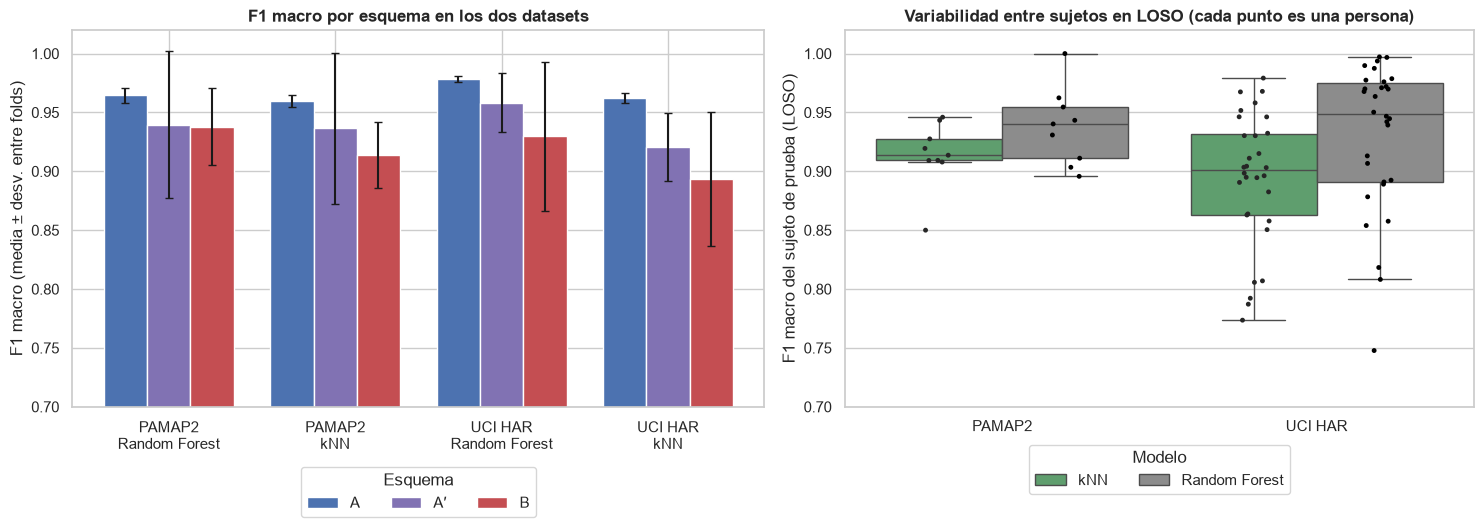

Hiperparámetros elegidos por kNN en UCI HAR (número de folds):
  A: {'k = 1, uniform': 4, 'k = 5, uniform': 1}
  B: {'k = 15, uniform': 11, 'k = 15, distance': 19}


In [41]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.1, 1]})

# Izquierda: F1 macro por esquema en los dos datasets
ax = ejes[0]
etiquetas = [f"{ds}\n{m}" for ds in ["PAMAP2", "UCI HAR"] for m in modelos_replica]
for i, esquema in enumerate(["A", "A′", "B"]):
    medias, desvs = [], []
    for ds, res in [("PAMAP2", resumen), ("UCI HAR", resumen_har)]:
        r = res[res["esquema"] == esquema].set_index("modelo")
        medias += list(r.loc[modelos_replica, "f1_fold_media"])
        desvs += list(r.loc[modelos_replica, "f1_fold_std"])
    ax.bar(np.arange(4) + (i - 1) * 0.26, medias, 0.26, yerr=desvs, capsize=3,
           color=colores_esq[esquema], label=esquema)
ax.set_xticks(np.arange(4), etiquetas)
ax.set_ylim(0.7, 1.02)
ax.set_ylabel("F1 macro (media ± desv. entre folds)")
ax.set_title("F1 macro por esquema en los dos datasets")
ax.legend(title="Esquema", ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.14))

# Derecha: F1 por sujeto en LOSO (variabilidad entre personas)
ax = ejes[1]
filas = []
for ds, pr in [("PAMAP2", principal), ("UCI HAR", pred_har)]:
    pf = evaluacion.metricas_por_fold(pr[pr["esquema"] == "B"])
    pf = pf[pf["modelo"].isin(["rf", "knn"])].assign(dataset=ds)
    filas.append(pf)
por_sujeto_ds = pd.concat(filas)
por_sujeto_ds["modelo"] = por_sujeto_ds["modelo"].map(NOMBRES)
sns.boxplot(data=por_sujeto_ds, x="dataset", y="f1_macro", hue="modelo", ax=ax,
            fliersize=0, palette=["#55A868", "#8C8C8C"])
sns.stripplot(data=por_sujeto_ds, x="dataset", y="f1_macro", hue="modelo", ax=ax,
              dodge=True, palette="dark:black", size=3.5, legend=False)
ax.set_ylim(0.7, 1.02)
ax.set_xlabel("")
ax.set_ylabel("F1 macro del sujeto de prueba (LOSO)")
ax.set_title("Variabilidad entre sujetos en LOSO (cada punto es una persona)")
ax.legend(title="Modelo", ncols=2, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
guardar_figura(fig, "replica_01_comparacion_datasets", FIGURAS)
plt.show()

from collections import Counter  # conteo de hiperparámetros elegidos por fold
print("Hiperparámetros elegidos por kNN en UCI HAR (número de folds):")
for esquema in ["A", "B"]:
    p = json.loads((CARPETA_FASE5 / f"params_{esquema}_knn_ninguno.json").read_text())
    conteo = Counter(f"k = {x['modelo__n_neighbors']}, {x['modelo__weights']}" for x in p)
    print(f"  {esquema}: {dict(conteo)}")

A la izquierda, el F1 de cada esquema en los dos datasets; a la derecha, el F1 de cada persona cuando es el sujeto de prueba en LOSO. La caja de UCI HAR es mucho más alta porque hay 30 personas y algunas se reconocen bastante peor que el resto (con Random Forest, el sujeto 14 obtiene 0.75).

#### ¿Se repite lo que vimos en PAMAP2?

**La fuga aparece igual, e incluso un poco mayor.** La brecha A − B es de 0.049 con Random Forest y 0.069 con kNN, contra 0.026 y 0.045 en PAMAP2. Tener más sujetos y clases equilibradas no la hace desaparecer: la fuga viene de cómo se evalúa (ventanas traslapadas del mismo sujeto a ambos lados), no de las particularidades de PAMAP2.

**El criterio de relevancia da la misma respuesta en los dos datasets.** Para kNN la brecha supera la desviación entre sujetos (0.069 contra 0.057); para Random Forest no (0.049 contra 0.063). Con 30 personas la desviación entre sujetos es casi el doble que con 9: al haber más gente, aparecen más personas atípicas.

**La descomposición se parece, con dos diferencias:**
- **Vecindad (A − A′).** Con Random Forest es de 0.020, casi igual que en PAMAP2 (0.025). Con kNN se duplica (0.042). Aquí sí se ve lo que predecía la hipótesis previa: kNN eligió `k = 1` en 4 de los 5 folds de A y `k = 15` en los 30 folds de B, y es el modelo con más fuga por vecindad. Una posible causa, que no comprobamos, son las ventanas más cortas (2.56 s): dos ventanas vecinas comparten 1.28 s de señal y el resto de la ventana tiene poco tiempo para diferenciarse.
- **Personas (A′ − B).** Ya no es casi nula en Random Forest (0.029, contra 0.002 en PAMAP2). Una posible explicación, tampoco comprobada: en PAMAP2 hay tres sensores en distintas partes del cuerpo y RF puede quedarse con los más estables entre personas; en UCI HAR hay un solo teléfono en la cintura y no tiene de dónde elegir.

**Lo que se puede y no se puede concluir.** El patrón cualitativo se repite: la partición aleatoria infla el F1, una parte se explica por ventanas vecinas y otra por personas nuevas, y kNN muestra el mecanismo de copiar a la gemela. Las cifras exactas, en cambio, no se pueden comparar directamente entre datasets: cambian los sensores, la ventana, el número de actividades (6 contra 12) y las características (561 de los autores contra 196 nuestras). Las dos explicaciones anteriores son hipótesis; este análisis no las pone a prueba.

## 7. Conclusiones y limitaciones

### Respuesta corta a cada pregunta

**P1. ¿Cuánto cae el F1 macro de A a B?** Entre 0.026 (Random Forest) y 0.049 (SVM); kNN cae 0.045. La fuga es relevante en kNN (la brecha supera la desviación entre sujetos), apenas en SVM, y depende del sujeto 109 en Random Forest. Unos 0.024 de la caída se deben a ventanas vecinas y son iguales en los tres modelos; el resto, que es cero en RF y ≈ 0.02 en SVM y kNN, es la dificultad real de reconocer a una persona nueva.

**P2. ¿Qué actividades son las más afectadas?** Las posturas y tareas domésticas: *sentado*, *de pie*, *planchar* y *aspirar*. En *sentado*, por ejemplo, casi toda la caída de Random Forest (0.091 de 0.095) es fuga por vecindad. Las actividades dinámicas (caminar, correr, bicicleta) pierden solo 0.01–0.02. *Saltar cuerda* solo se desploma con SVM, y la causa es una persona (el sujeto 108), no la fuga.

**P3. ¿Qué características siguen siendo útiles con personas nuevas?** Las de aceleración de la muñeca y el pecho, y las del giroscopio y el acelerómetro del tobillo. La temperatura y la frecuencia cardiaca casi no aportan en LOSO, y quitarlas no cambia el desempeño. Con 36 de 196 atributos se conserva ≥ 95 % del F1 de LOSO; PCA no mejora a la selección.

**Réplica en UCI HAR.** El patrón se repite con 30 sujetos y clases balanceadas: la brecha A − B es de 0.049 (RF) y 0.069 (kNN), y el criterio de relevancia da la misma respuesta (sí para kNN, no para RF).

**Mensaje general.** Con partición aleatoria de ventanas el F1 se infla de 3 a 7 puntos. Para estimar el desempeño con usuarios nuevos hay que separar por sujeto. La exactitud en LOSO es de 0.92–0.93, así que el problema sigue siendo resoluble, pero la cifra de la partición aleatoria (≈ 0.96–0.97) no es la que verá un usuario nuevo.

### Qué no se puede concluir

- **Que los modelos con mayor brecha tienen más fuga.** La mitad de la brecha de SVM y kNN es diferencia entre personas; la parte que sí es fuga (A − A′) es igual en los tres.
- **Que un modelo es mejor que otro con personas nuevas.** En B las diferencias entre modelos (0.01–0.02) son menores que la desviación entre sujetos, y el ganador cambia según el esquema: SVM en A, RF en B y kNN en C.
- **Que la conclusión sobre Random Forest es firme.** Pasa de «no relevante» a «relevante» al quitar un solo sujeto (el 109).
- **Que A′ mide toda la fuga.** A′ quita la ventana inmediatamente vecina, pero las ventanas del mismo tramo siguen pareciéndose entre sí, así que A′ − B puede contener todavía algo de fuga «a distancia».
- **Que el criterio «brecha > desviación entre sujetos» sea una prueba estadística.** Es una regla fijada en la propuesta. Con 9 folds la propia desviación es imprecisa, y no calculamos intervalos de confianza ni pruebas de hipótesis.
- **Que las explicaciones que dimos para UCI HAR (ventanas más cortas, un solo sensor) sean ciertas.** Son hipótesis que este análisis no pone a prueba.
- **Que estas cifras valen fuera de este contexto,** es decir, con otros dispositivos, otras actividades o personas en su vida diaria.

### Limitaciones

1. **Pocos sujetos.** PAMAP2 tiene 9 personas, y una de ellas (el 109) aporta 1.1 minutos y una sola actividad. Con tan pocos folds, un solo sujeto mueve la media y la desviación de LOSO: el 109 cambia la conclusión de Random Forest y el 108 (zurdo) explica casi toda la caída de SVM en *saltar cuerda*.
2. **Clases con pocas personas.** *Saltar cuerda* la hicieron 5 sujetos y *correr* 6. El F1 de esas clases en LOSO depende de 5 o 6 personas, y en los folds donde faltan hay que elegir cómo promediar: por fold sobre las clases presentes o agrupado. Las dos formas difieren hasta 0.02, que es del orden de la brecha de RF.
3. **Actividades de laboratorio.** Las actividades siguieron un protocolo guiado, con transiciones descartadas (32.4 % de las muestras tenían etiqueta 0). En la vida diaria las actividades se mezclan y duran menos, así que el desempeño real sería menor que el de cualquiera de los esquemas.
4. **Ventana fija.** Solo probamos ventanas de 5.12 s con 50 % de traslape. La fuga por vecindad depende del traslape: es de esperar que con 75 % fuera mayor y que sin traslape se redujera, pero no lo comprobamos, porque no variamos ni el largo ni el traslape.
5. **A′ es una aproximación.** Solo purga una ventana a cada lado del bloque de prueba. Además, los bloques de los extremos (inicio y fin de cada actividad) son más difíciles en todos los esquemas, por eso la desviación entre folds de A′ (≈ 0.06) es mucho mayor que la de A (≈ 0.005).
6. **Esquema C con una sola selección de sujetos.** El hold-out de 101, 102 y 107 da una sola cifra por modelo, sin variabilidad. No hicimos la variante repetida (combinaciones de 3 sujetos), así que no sabemos cuánto cambiaría C con otros sujetos de prueba. Por eso usamos LOSO como respuesta principal y C como contraste.
7. **Búsqueda de hiperparámetros reducida.** Las rejillas son pequeñas (4 a 6 combinaciones por modelo) para mantener igual el presupuesto de todos. Con rejillas más amplias el orden entre modelos podría cambiar, aunque es poco probable que cambie la brecha por vecindad, que no depende del algoritmo.
8. **Características elegidas a mano.** Usamos 196 atributos estadísticos y espectrales. Otros atributos, o modelos que aprenden de la señal cruda (redes convolucionales o recurrentes), podrían tener otra brecha. Las conclusiones de P3 se refieren a este conjunto.
9. **Importancia con atributos correlacionados.** La importancia por permutación subestima a los atributos que tienen un sustituto correlacionado, por eso el ranking individual contradice en parte a RFE. Las conclusiones de P3 se apoyan en los grupos de sensores, que son más estables. RFE avanza de 10 en 10, así que el mínimo real está entre 27 y 36 atributos.
10. **Preprocesamiento de la frecuencia cardiaca.** La FC se mide a ≈ 9 Hz y se interpoló a 100 Hz. Es una señal muy suavizada; su poca utilidad en LOSO puede deberse en parte a eso.
11. **El segundo dataset no es directamente comparable.** UCI HAR usa otro sensor (un teléfono en la cintura), otra ventana (2.56 s), 6 actividades en lugar de 12 y las 561 características de los autores, normalizadas con todo el dataset. La réplica permite comparar el patrón, no las cifras.

## 8. Declaración de uso de IA generativa

En este proyecto se usaron herramientas de IA generativa de Anthropic: **Claude** (Opus 5.5).

**Para qué se usaron:**
- **Planeación:** organizar el proyecto por fases a partir de la propuesta y de la retroalimentación de los profesores, incluido el diseño del esquema A′ para separar la fuga por vecindad de la diferencia entre personas.
- **Código:** escribir y revisar los módulos de `src/` (carga, ventanas, características, particiones, experimentos y evaluación) y las celdas de este notebook, incluidas las verificaciones contra la fuga (`assert` sobre sujetos e índices de ventana).
- **Redacción:** borradores de las explicaciones en markdown, de las interpretaciones de las figuras y de esta sección de conclusiones.
- **Revisión:** detectar errores e inconsistencias entre el texto y las cifras, por ejemplo afirmaciones que las tablas contradecían.

**Qué hizo el autor:**
- Definió las preguntas de investigación, la métrica y el criterio de relevancia en la propuesta, y decidió cómo atender cada comentario de los profesores.
- Tomó las decisiones de alcance: no usar SMOTE, conservar al sujeto 109, confirmar el segundo dataset y ejecutar los experimentos pesados en scripts.
- Revisó el código, ejecutó el notebook completo y comprobó que las cifras del análisis exploratorio coincidieran con las calculadas de forma independiente.
- Interpretó con sus propias palabras los resultados de P1 antes de que se redactara la conclusión, y revisó y validó todos los resultados y textos.

Todas las cifras del notebook salen del código ejecutado sobre los datos; ninguna fue escrita a mano por la herramienta. El autor es responsable del contenido final.